# Telco Customer Churn: Optimization, Explainability and Decision Support

**Author:** Erick Olivo · **Course:** Aprendizaje Automático · **Assignment:** Task 7

**Guiding principle:** the model *ranks* customers by churn risk; the business *decides* whom to
contact. Model quality is measured with threshold-free metrics (PR-AUC, ROC-AUC); the decision
threshold is set afterwards with an explicit, declared cost model.

| Decision | Choice | Reason |
|:--|:--|:--|
| Split | 80/20 stratified train/test; 5-fold stratified CV on train for every comparison | Test stays locked until the final model and threshold are fixed |
| EDA | Training set only | No information from test influences any decision |
| Preprocessing | Cleaning and feature engineering inside the pipeline (shared module) | Identical transformations in training, evaluation and Streamlit |
| Imbalance | No resampling; handled by the decision threshold | Keeps probabilities interpretable for the app and for SHAP |
| Tuning metric | PR-AUC (average precision) | Focuses on the churn class and does not depend on a threshold |
| Tuned model | LightGBM | Rich hyperparameter space, fast, exact TreeSHAP support |
| Optimizer comparison | Same objective, folds, pipeline and budget; only the search strategy changes | Controlled experiment |
| Multi-objective | Maximize PR-AUC, minimize model complexity (total leaves) | Deterministic proxy of inference cost; latency measured afterwards |

**Sections:** 0 Setup · 1 Data · 2 Split · 3 EDA · 4 Pipeline · 5 Model comparison ·
6 Hyperparameter optimization · 7 Multi-objective optimization · 8 Decision threshold ·
9 Final test evaluation · 10 SHAP · 11 LIME · 12 XAI comparison · 13 Export · 14 Conclusions

## 0. Setup

In [1]:
%pip install -q optuna shap lime lightgbm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import json
import time
import warnings
import zipfile
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import shap
import lightgbm
from lightgbm import LGBMClassifier
from lime.lime_tabular import LimeTabularExplainer
from scipy import stats
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
N_FOLDS = 5
N_JOBS = -1
TEST_SIZE = 0.20
CHURN_COLORS = {0: "#4C72B0", 1: "#DD8452"}
STRATEGY_COLORS = {"Grid": "#4C72B0", "Random": "#55A868", "TPE": "#C44E52", "NSGA-II": "#8172B3"}
BASE_LGBM = dict(random_state=SEED, n_jobs=1, verbose=-1, subsample_freq=1, deterministic=True, force_row_wise=True)

### 0.1 Shared module

Cleaning, feature engineering, pipeline construction and explanation helpers live in
`telco_churn.py`. The exported pipeline references these classes, so the same file is shipped
with the Streamlit app: training and serving use exactly the same code.

In [3]:
%%writefile telco_churn.py
"""Shared components for the Telco churn project (training notebook and Streamlit app)."""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET = "Churn"
ID_COL = "customerID"
NUMERIC_INPUTS = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_INPUTS = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod",
]
INPUT_COLUMNS = CATEGORICAL_INPUTS[:4] + ["tenure"] + CATEGORICAL_INPUTS[4:] + ["MonthlyCharges", "TotalCharges"]
INTERNET_ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                   "StreamingTV", "StreamingMovies"]
ENGINEERED = ["avg_monthly_spend", "price_increase", "n_services"]


class TelcoCleaner(BaseEstimator, TransformerMixin):
    """Deterministic cleaning rules derived from the EDA. Learns nothing from data."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        total = pd.to_numeric(X["TotalCharges"].astype(str).str.strip().replace("", np.nan), errors="coerce")
        X["TotalCharges"] = total.where(~(total.isna() & (X["tenure"] == 0)), 0.0).astype(float)
        X["tenure"] = X["tenure"].astype(float)
        X["MonthlyCharges"] = X["MonthlyCharges"].astype(float)
        X["SeniorCitizen"] = X["SeniorCitizen"].replace({0: "No", 1: "Yes", "0": "No", "1": "Yes"}).astype(str)
        X[INTERNET_ADDONS] = X[INTERNET_ADDONS].replace("No internet service", "No")
        X["MultipleLines"] = X["MultipleLines"].replace("No phone service", "No")
        return X


class FeatureBuilder(BaseEstimator, TransformerMixin):
    """Adds three business-readable features. Set enabled=False for the ablation study."""

    def __init__(self, enabled=True):
        self.enabled = enabled

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if not self.enabled:
            return X
        X = X.copy()
        has_history = X["tenure"] > 0
        X["avg_monthly_spend"] = np.where(has_history, X["TotalCharges"] / X["tenure"].where(has_history, 1),
                                          X["MonthlyCharges"])
        X["price_increase"] = X["MonthlyCharges"] - X["avg_monthly_spend"]
        services = (X[["PhoneService", "MultipleLines"] + INTERNET_ADDONS] == "Yes").sum(axis=1)
        X["n_services"] = (services + (X["InternetService"] != "No")).astype(float)
        return X


def _combine(feature, category):
    return f"{feature}={str(category).replace(' ', '_')}"


def build_preprocessor(scale=False):
    numeric = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric.append(("scaler", StandardScaler()))
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False,
                                 feature_name_combiner=_combine)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(numeric), make_column_selector(dtype_include="number")),
        ("cat", categorical, make_column_selector(dtype_exclude="number")),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


def build_pipeline(model, engineered=True, scale=False):
    return Pipeline([
        ("clean", TelcoCleaner()),
        ("features", FeatureBuilder(enabled=engineered)),
        ("prep", build_preprocessor(scale=scale)),
        ("model", model),
    ])


def original_feature(name):
    """Map a transformed column (e.g. 'Contract=Month-to-month') to its original feature."""
    return name.split("=")[0]


def aggregate_by_feature(values, feature_names):
    """Sum contributions of one-hot columns back to their original feature."""
    frame = pd.DataFrame(np.atleast_2d(values), columns=list(feature_names))
    return frame.T.groupby(original_feature).sum().T


def _fmt(value):
    return f"{value:,.2f}".rstrip("0").rstrip(".") if isinstance(value, (int, float, np.floating)) else str(value)


def explain_in_words(contributions, customer, top=3, min_effect=0.05):
    """Plain-language summary from per-feature contributions (positive = raises churn risk).

    Contributions below `min_effect` (log-odds) are ignored as negligible.
    """
    ordered = contributions.sort_values(ascending=False)
    up = [f"{f} = {_fmt(customer.get(f, ''))}" for f, v in ordered.items() if v >= min_effect][:top]
    down = [f"{f} = {_fmt(customer.get(f, ''))}" for f, v in ordered[::-1].items() if v <= -min_effect][:top]
    text = []
    if up:
        text.append("Risk increases mainly because of: " + "; ".join(up) + ".")
    if down:
        text.append("Risk decreases because of: " + "; ".join(down) + ".")
    return " ".join(text)

Writing telco_churn.py


In [4]:
import importlib
import telco_churn
importlib.reload(telco_churn)
from telco_churn import (
    TARGET, ID_COL, INPUT_COLUMNS, NUMERIC_INPUTS, CATEGORICAL_INPUTS, ENGINEERED,
    TelcoCleaner, FeatureBuilder, build_pipeline, aggregate_by_feature, explain_in_words,
)

pd.DataFrame({"version": {lib: version(lib) for lib in
              ["scikit-learn", "lightgbm", "optuna", "shap", "lime", "pandas", "numpy"]}})

,version
scikit-learn,1.6.1
lightgbm,4.6.0
optuna,5.0.0
shap,0.54.1
lime,0.2.0.1
pandas,2.2.3
numpy,2.4.6


## 1. Data Loading and Schema Validation

In [5]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Aprendizaje_automatico")
    ZIP_PATH = PROJECT_DIR / "datasets/TelcoDataset.zip"
    ARTIFACTS_DIR = PROJECT_DIR / "telco_churn_artifacts"
except ImportError:
    ZIP_PATH = Path("TelcoDataset.zip")
    ARTIFACTS_DIR = Path("artifacts")

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall("data")
DATA_FILE = next(p for p in Path("data").rglob("*.csv") if "__MACOSX" not in p.parts)
raw = pd.read_csv(DATA_FILE)

expected = set(INPUT_COLUMNS) | {ID_COL, TARGET}
assert expected == set(raw.columns), f"Schema mismatch: {expected ^ set(raw.columns)}"
assert raw[ID_COL].is_unique
assert set(raw[TARGET]) == {"Yes", "No"}

Markdown(f"**{DATA_FILE.name}**: {raw.shape[0]:,} rows, {raw.shape[1]} columns. Schema validated.")

Mounted at /content/drive


**WA_Fn-UseC_-Telco-Customer-Churn.csv**: 7,043 rows, 21 columns. Schema validated.

In [6]:
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


## 2. Stratified Train/Test Split

The split happens before any analysis. Test is not used again until Section 9.
The 5 CV folds are generated once and reused by every model and optimizer.

In [7]:
X = raw[INPUT_COLUMNS].copy()
y = (raw[TARGET] == "Yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

CV = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
CV_SPLITS = list(CV.split(X_train, y_train))

pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "churn_rate": [y_train.mean(), y_test.mean()],
    "share": [len(X_train) / len(X), len(X_test) / len(X)],
}, index=["train", "test"])

,rows,churn_rate,share
train,5634,0.2654,0.7999
test,1409,0.2654,0.2001


## 3. Exploratory Data Analysis (training set only)

### 3.1 Data quality

In [8]:
eda_raw = X_train.assign(Churn=y_train)
blank = eda_raw.select_dtypes(exclude="number").apply(lambda s: s.astype(str).str.strip().eq("").sum())
quality = pd.DataFrame({
    "dtype": eda_raw.dtypes.astype(str),
    "missing": eda_raw.isna().sum(),
    "blank_strings": blank.reindex(eda_raw.columns, fill_value=0),
    "n_unique": eda_raw.nunique(),
})
display(quality[(quality["missing"] > 0) | (quality["blank_strings"] > 0)])
display(eda_raw.loc[eda_raw["TotalCharges"].astype(str).str.strip().eq(""), ["tenure", "MonthlyCharges", "TotalCharges", "Contract"]])

,dtype,missing,blank_strings,n_unique
TotalCharges,object,0,8,5276


,tenure,MonthlyCharges,TotalCharges,Contract
6670,0,73.3500,,Two year
4380,0,20.0000,,Two year
3826,0,25.3500,,Two year
488,0,52.5500,,Two year
1082,0,25.7500,,Two year
1340,0,56.0500,,Two year
6754,0,61.9000,,Two year
3331,0,19.8500,,Two year


In [9]:
redundant = pd.DataFrame({
    "No internet service": (eda_raw[["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
                                     "StreamingTV", "StreamingMovies"]] == "No internet service").sum(),
})
display(redundant.T)
display(pd.crosstab(eda_raw["PhoneService"], eda_raw["MultipleLines"]))

,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
No internet service,1214,1214,1214,1214,1214,1214


MultipleLines,No,No phone service,Yes
PhoneService,,,
No,0,559,0
Yes,2685,0,2390


**Findings.** The only quality issue in train is 8 blank `TotalCharges`, all with `tenure = 0`
(new customers not yet billed), so the correct value is 0, not an imputed mean. There are no
true missing values. `No internet service` appears in the same 1,214 rows for all six add-on
services and `No phone service` matches `PhoneService = No` exactly: these levels are redundant
with the parent feature.

### 3.2 Cleaning rules

| Issue | Rule | Where |
|:--|:--|:--|
| `TotalCharges` stored as text, blanks when `tenure = 0` | Convert to numeric; blank with `tenure = 0` becomes 0 | `TelcoCleaner` |
| `SeniorCitizen` encoded as 0/1 | Map to `No`/`Yes` (categorical like the other binary flags) | `TelcoCleaner` |
| `No internet service`, `No phone service` | Map to `No`; the information is already in `InternetService` / `PhoneService` | `TelcoCleaner` |
| `customerID` | Excluded (identifier) | Column selection |

The rules are deterministic, so applying them inside the pipeline causes no leakage. The EDA below
uses the same `TelcoCleaner` and `FeatureBuilder` as the model.

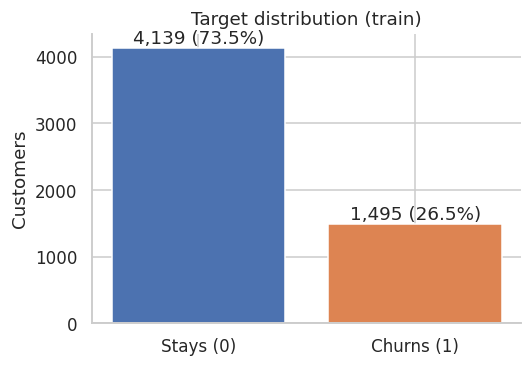

In [10]:
eda = FeatureBuilder().transform(TelcoCleaner().transform(X_train)).assign(Churn=y_train)
base_rate = y_train.mean()

fig, ax = plt.subplots(figsize=(5, 3.5))
counts = eda["Churn"].value_counts().sort_index()
ax.bar(["Stays (0)", "Churns (1)"], counts.values, color=[CHURN_COLORS[0], CHURN_COLORS[1]])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,} ({v / len(eda):.1%})", ha="center", va="bottom")
ax.set(title="Target distribution (train)", ylabel="Customers")
plt.tight_layout()
plt.show()

**Findings.** 26.5 % of training customers churn. A model that always predicts "stays" reaches
73.5 % accuracy without learning anything, which is why accuracy is not used to select models.

### 3.3 Numerical features

Churn,median_stays,median_churns,mannwhitney_p,skew
tenure,38.0000,10.0000,0.0000,0.2374
MonthlyCharges,64.4000,79.9500,0.0000,-0.2244
TotalCharges,1686.1500,740.3000,0.0000,0.9490
avg_monthly_spend,63.9770,79.7742,0.0000,-0.2145
price_increase,0.0000,0.0000,0.9713,-0.1252
n_services,4.0000,4.0000,0.9680,0.2145


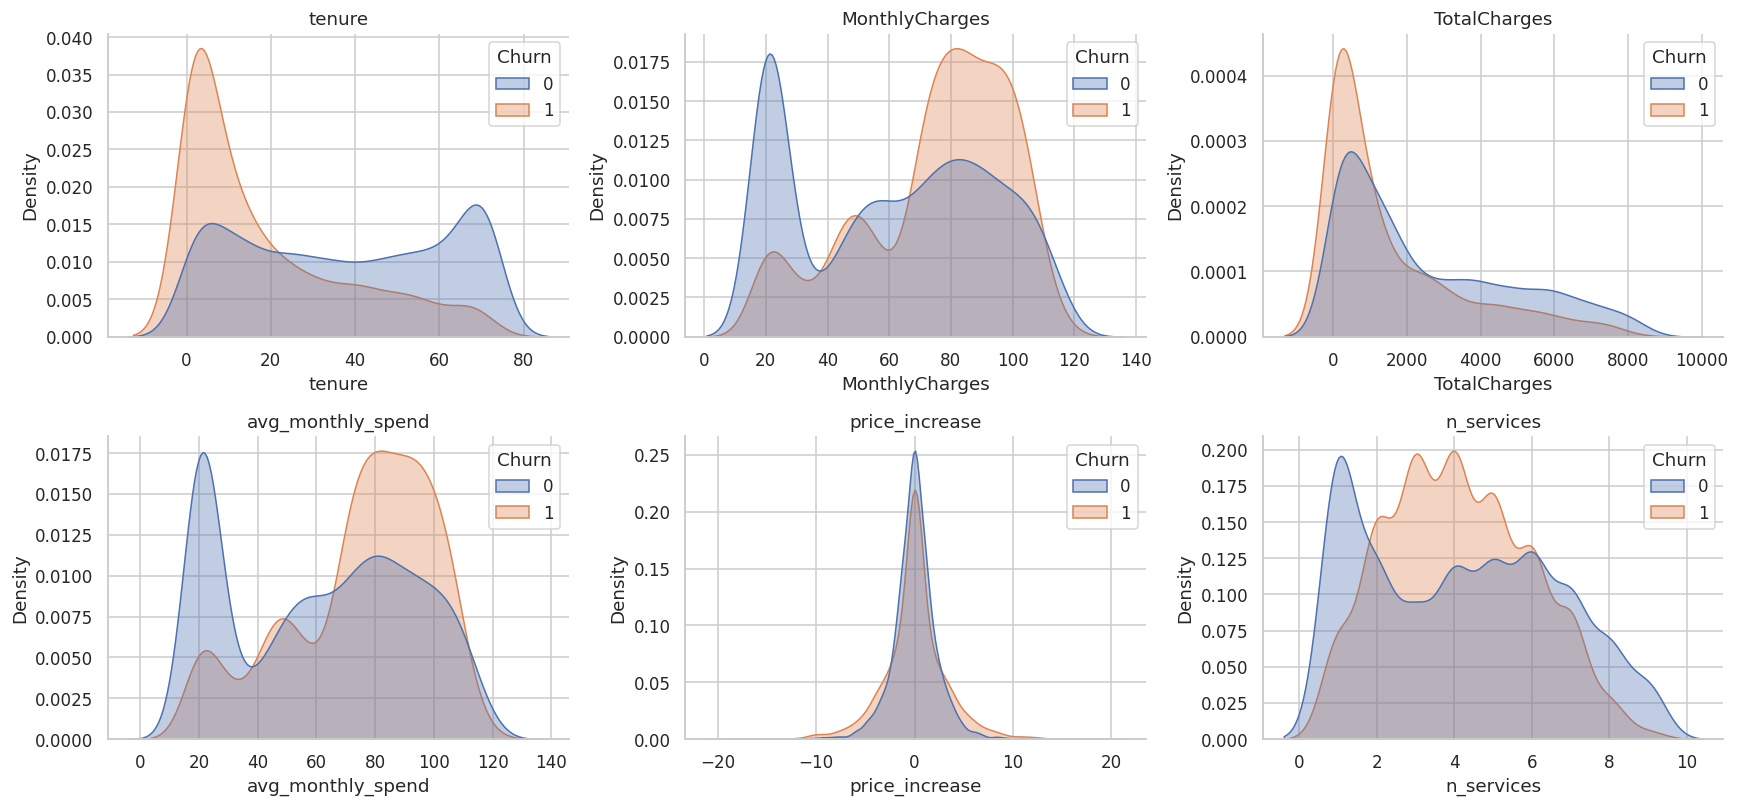

In [11]:
numeric_eda = NUMERIC_INPUTS + ENGINEERED
summary = eda.groupby("Churn")[numeric_eda].median().T.rename(columns={0: "median_stays", 1: "median_churns"})
summary["mannwhitney_p"] = [stats.mannwhitneyu(eda.loc[eda.Churn == 0, c], eda.loc[eda.Churn == 1, c]).pvalue
                            for c in numeric_eda]
summary["skew"] = eda[numeric_eda].skew()
display(summary)

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5))
for ax, col in zip(axes.flat, numeric_eda):
    sns.kdeplot(data=eda, x=col, hue="Churn", palette=CHURN_COLORS, fill=True, common_norm=False,
                alpha=0.35, ax=ax, warn_singular=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Findings.**

- Churners have a median tenure of 10 months against 38 for those who stay, and pay more per
  month (80 vs 64). Both differences are highly significant (Mann-Whitney).
- `MonthlyCharges` is bimodal: a peak near 20 (phone only) and a broad mass at 70-105 (internet,
  mostly fiber), where churn concentrates.
- **Engineered features:** `avg_monthly_spend` is almost a copy of `MonthlyCharges`, and
  `price_increase` and `n_services` show no difference between groups (p ≈ 0.97). In this dataset
  `TotalCharges ≈ tenure × MonthlyCharges`, so there is no price-change signal to extract. The
  ablation in Section 4.1 tests this formally.

### 3.4 Categorical features

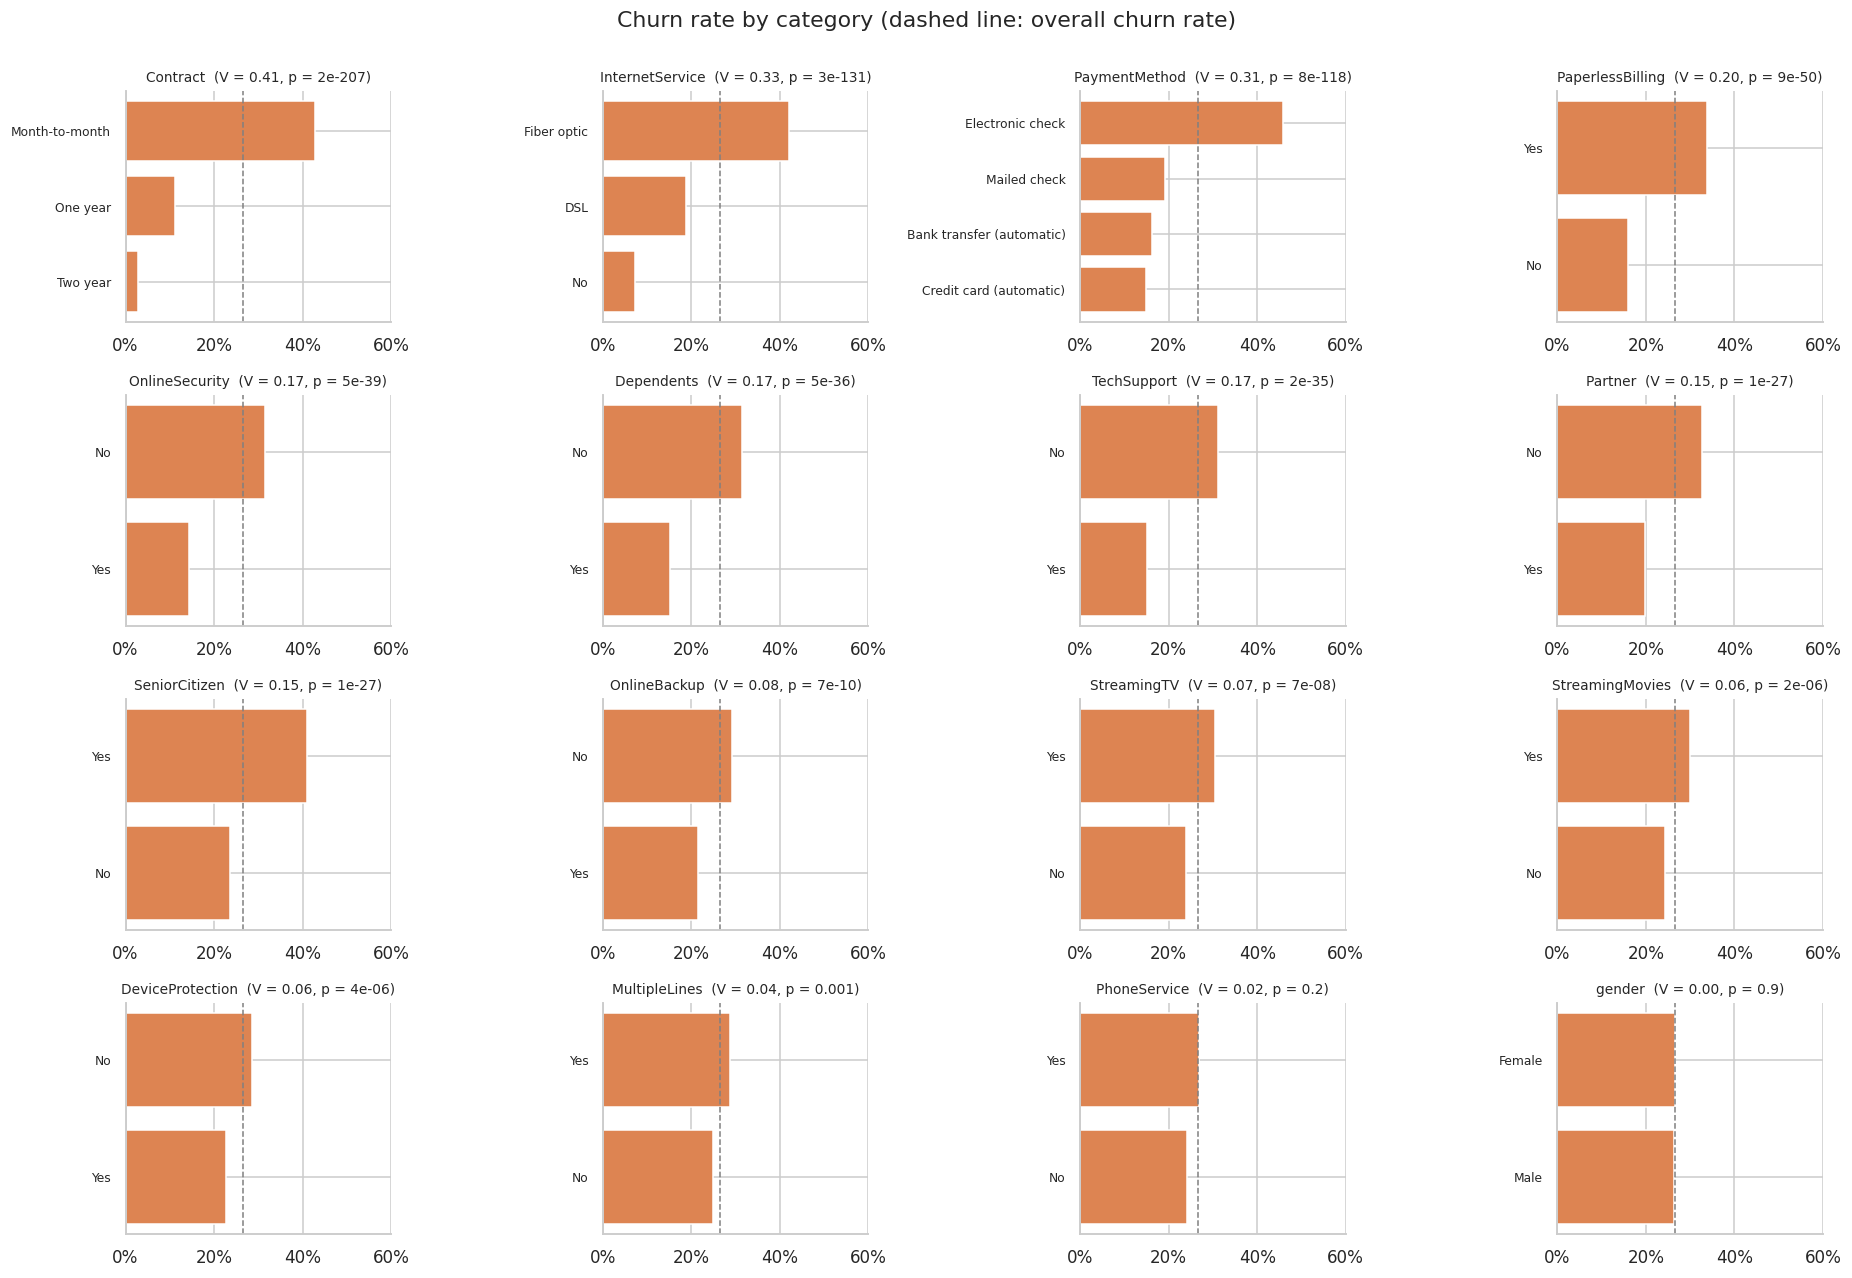

In [12]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2, p, _, _ = stats.chi2_contingency(table)
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), p

categorical_eda = CATEGORICAL_INPUTS
association = pd.DataFrame([(c, *cramers_v(eda[c], eda["Churn"])) for c in categorical_eda],
                           columns=["feature", "cramers_v", "p_value"]).set_index("feature")
association = association.sort_values("cramers_v", ascending=False)

ncols = 4
nrows = int(np.ceil(len(categorical_eda) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(17, nrows * 2.9))
for ax, col in zip(axes.flat, association.index):
    rate = eda.groupby(col)["Churn"].mean().sort_values()
    ax.barh(rate.index.astype(str), rate.values, color=CHURN_COLORS[1])
    ax.axvline(base_rate, color="gray", ls="--", lw=1)
    ax.set_title(f"{col}  (V = {association.loc[col, 'cramers_v']:.2f}, p = {association.loc[col, 'p_value']:.1g})",
                 fontsize=9)
    ax.set_xlim(0, 0.6)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.flat[len(categorical_eda):]:
    ax.set_visible(False)
fig.suptitle("Churn rate by category (dashed line: overall churn rate)", y=1.0)
plt.tight_layout()
plt.show()

**Findings.**

- **Contract** (V = 0.41): ≈ 43 % churn month-to-month vs ≈ 11 % (one year) and ≈ 3 % (two years).
- **InternetService** (V = 0.33): fiber ≈ 42 %, DSL ≈ 19 %, no internet ≈ 7 %.
- **PaymentMethod** (V = 0.31): electronic check ≈ 45 % vs 15-19 % for the other methods.
- Moderate effects: `PaperlessBilling`, `OnlineSecurity`, `TechSupport`, `Dependents`, `Partner`, `SeniorCitizen` (V 0.15-0.20).
- `PhoneService` (p = 0.2) and `gender` (p = 0.9) show no association. They are kept: the models
  can ignore them, and removing them would be a selection decision without a clear gain.

### 3.5 Interactions and redundancy

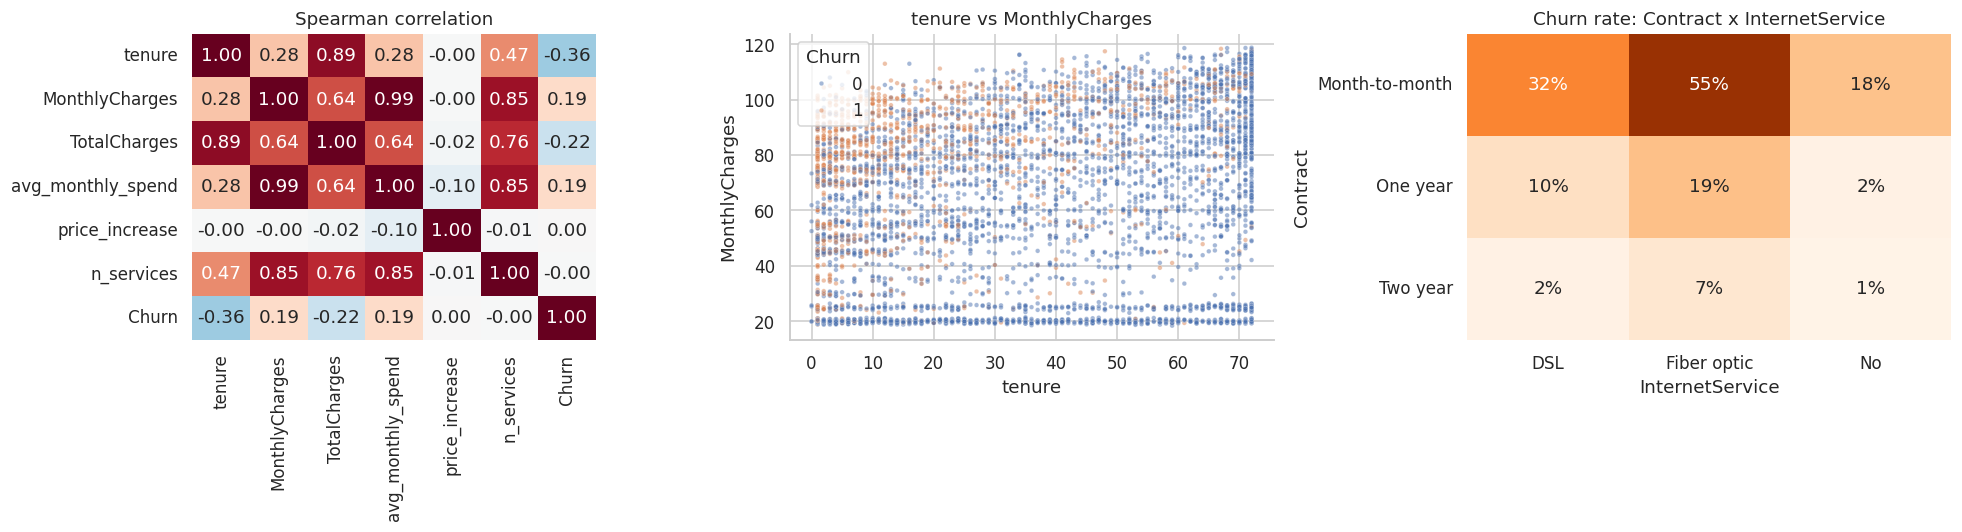

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.2, 1.2]})
sns.heatmap(eda[numeric_eda + ["Churn"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, cbar=False, ax=axes[0])
axes[0].set_title("Spearman correlation")

sns.scatterplot(data=eda.sample(frac=1, random_state=SEED), x="tenure", y="MonthlyCharges", hue="Churn",
                palette=CHURN_COLORS, s=9, alpha=0.5, ax=axes[1])
axes[1].set_title("tenure vs MonthlyCharges")

pivot = eda.pivot_table(index="Contract", columns="InternetService", values="Churn", aggfunc="mean")
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Oranges", vmin=0, vmax=0.6, cbar=False, ax=axes[2])
axes[2].set_title("Churn rate: Contract x InternetService")
axes[2].tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

**Findings.** `TotalCharges` is strongly correlated with `tenure` (0.89), so it adds little new
information. The highest-risk region is **short tenure with high monthly charges**. Contract and
internet type interact: month-to-month fiber customers churn at 55 %, two-year DSL customers at 2 %.
This interaction is a reason to test a tree-based model that captures it without manual terms.

## 4. Preprocessing Pipeline

```
raw input ─► TelcoCleaner ─► FeatureBuilder ─► ColumnTransformer ─► model
               cleaning        optional         numeric: median imputer (+ scaler for linear models)
                                                categorical: mode imputer + one-hot (binary: single column)
```

- Every learned step (imputers, scaler, encoder) is fitted inside each CV fold, never on validation or test data.
- Scaling is applied only to Logistic Regression. Tree models do not need it, and unscaled inputs keep SHAP values in original units (months, dollars).
- `handle_unknown="ignore"` makes the deployed model robust to unseen categories.
- `FeatureBuilder` adds `avg_monthly_spend`, `price_increase` and `n_services`. They are a hypothesis,
  so they are kept only if the ablation in 4.1 shows a gain.

In [14]:
example = build_pipeline(LogisticRegression(), scale=True)
example.fit(X_train, y_train)
transformed = example[:-1].transform(X_train.head())
display(example)
Markdown(f"Transformed matrix: **{transformed.shape[1]} columns** from {len(INPUT_COLUMNS)} raw inputs.")

Pipeline(steps=[('clean', TelcoCleaner()), ('features', FeatureBuilder()),
                ('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7f602219f0e0>),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='if_binary',
                                                                                 feature_name_combiner=<function _combine at 0x7f602218e2a0>,
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7f602064a710>)],
                                   verbose_feature_names_out=False)),
                ('model', LogisticRegression())])

Transformed matrix: **29 columns** from 19 raw inputs.

In [15]:
transformed

,tenure,MonthlyCharges,TotalCharges,avg_monthly_spend,price_increase,n_services,gender=Male,SeniorCitizen=Yes,Partner=Yes,Dependents=Yes,PhoneService=Yes,MultipleLines=Yes,InternetService=DSL,InternetService=Fiber_optic,InternetService=No,OnlineSecurity=Yes,OnlineBackup=Yes,DeviceProtection=Yes,TechSupport=Yes,StreamingTV=Yes,StreamingMovies=Yes,Contract=Month-to-month,Contract=One_year,Contract=Two_year,PaperlessBilling=Yes,PaymentMethod=Bank_transfer_(automatic),PaymentMethod=Credit_card_(automatic),PaymentMethod=Electronic_check,PaymentMethod=Mailed_check
3738,0.1024,-0.5220,-0.2623,-0.5400,0.2269,-0.0722,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
3151,-0.7117,0.3375,-0.5036,0.3915,-0.6396,-0.5031,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
4860,-0.7932,-0.8090,-0.7499,-0.6461,-1.8679,-0.0722,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000
3867,-0.2640,0.2844,-0.1727,0.2766,0.0816,0.7896,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.0000
3810,-1.2816,-0.6763,-0.9894,-0.6746,0.0031,-0.9340,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000


### 4.1 Ablation: do the engineered features help?

Logistic Regression and LightGBM (default settings), same folds, with and without `avg_monthly_spend`, `price_increase` and `n_services`.

In [16]:
ablation = []
ABLATION_MODELS = {"Logistic Regression": (LogisticRegression(max_iter=2000), True),
                   "LightGBM": (LGBMClassifier(**BASE_LGBM), False)}
for name, (model, scale) in ABLATION_MODELS.items():
    for engineered in [False, True]:
        pipe = build_pipeline(model, engineered=engineered, scale=scale)
        scores = cross_validate(pipe, X_train, y_train, cv=CV_SPLITS, scoring=["average_precision", "roc_auc"],
                                n_jobs=N_JOBS)
        ablation.append({"model": name, "engineered_features": engineered,
                         "pr_auc": scores["test_average_precision"].mean(),
                         "pr_auc_std": scores["test_average_precision"].std(ddof=1),
                         "roc_auc": scores["test_roc_auc"].mean()})
ablation = pd.DataFrame(ablation)
gain = ablation.pivot(index="model", columns="engineered_features", values="pr_auc")
USE_ENGINEERED = bool((gain[True] > gain[False]).all())


def make_pipeline(model, scale=False):
    return build_pipeline(model, engineered=USE_ENGINEERED, scale=scale)


display(ablation)
Markdown(f"Decision: engineered features **{'kept' if USE_ENGINEERED else 'dropped'}** for all subsequent models.")

,model,engineered_features,pr_auc,pr_auc_std,roc_auc
0,Logistic Regression,False,0.6613,0.0214,0.8461
1,Logistic Regression,True,0.6592,0.0211,0.8455
2,LightGBM,False,0.6428,0.0233,0.8349
3,LightGBM,True,0.6267,0.0269,0.8328


Decision: engineered features **dropped** for all subsequent models.

**Decision: the engineered features are dropped.** They reduce PR-AUC for both models (LightGBM
0.643 → 0.627, Logistic Regression 0.661 → 0.659). As the EDA anticipated, they duplicate
existing information and add noise. The hypothesis was tested and rejected with evidence; the
`FeatureBuilder` step remains in the pipeline but is disabled, so the decision is traceable.

## 5. Model Comparison

All models use the same pipeline and the same 5 folds. Metrics are mean ± std over folds.
Threshold-dependent metrics (accuracy, precision, recall, F1) use the default 0.5.

| Model | Role |
|:--|:--|
| Dummy (stratified) | Lower bound: random guessing at the observed churn rate |
| Logistic Regression | Strong, interpretable linear baseline |
| Random Forest | Bagging ensemble; reference for feature importance (Section 12) |
| LightGBM | Gradient boosting; candidate for optimization |

In [17]:
MODELS = {
    "Dummy": make_pipeline(DummyClassifier(strategy="stratified", random_state=SEED)),
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=2000), scale=True),
    "Random Forest": make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                           random_state=SEED, n_jobs=1)),
    "LightGBM": make_pipeline(LGBMClassifier(**BASE_LGBM)),
}
SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

cv_rows, oof_proba = [], {}
for name, pipe in MODELS.items():
    res = cross_validate(pipe, X_train, y_train, cv=CV_SPLITS, scoring=SCORING, n_jobs=N_JOBS)
    row = {"model": name, "fit_time_s": res["fit_time"].mean()}
    for metric in SCORING:
        row[metric] = res[f"test_{metric}"].mean()
        row[f"{metric}_std"] = res[f"test_{metric}"].std(ddof=1)
    cv_rows.append(row)
    oof_proba[name] = cross_val_predict(pipe, X_train, y_train, cv=CV_SPLITS, method="predict_proba",
                                        n_jobs=N_JOBS)[:, 1]

model_comparison = pd.DataFrame(cv_rows).set_index("model")
display(model_comparison[list(SCORING) + ["fit_time_s"]].style.format("{:.4f}")
        .highlight_max(subset=list(SCORING), color="#d4e6f1"))

,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_time_s
model,,,,,,,
Dummy,0.6139,0.2748,0.2776,0.2762,0.5065,0.2686,0.1091
Logistic Regression,0.8023,0.6536,0.5431,0.5926,0.8461,0.6613,0.1567
Random Forest,0.8014,0.6700,0.4977,0.5708,0.8420,0.6527,4.2187
LightGBM,0.7952,0.6408,0.5211,0.5746,0.8349,0.6428,0.5545


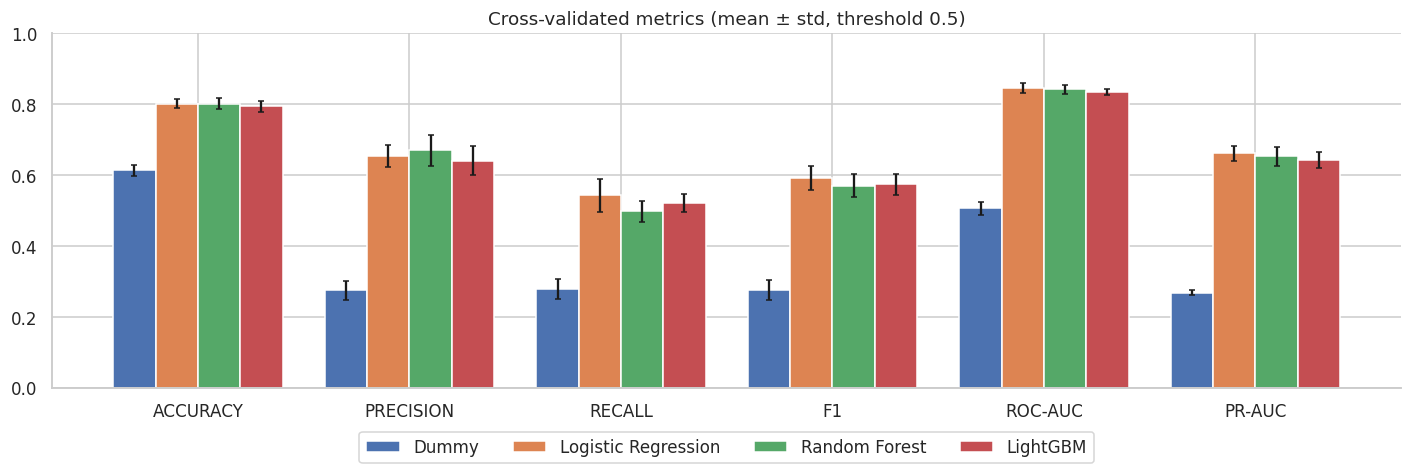

In [18]:
fig, ax = plt.subplots(figsize=(13, 4.5))
metrics = list(SCORING)
width = 0.2
for k, (name, row) in enumerate(model_comparison.iterrows()):
    pos = np.arange(len(metrics)) + (k - 1.5) * width
    ax.bar(pos, row[metrics], width, yerr=row[[f"{m}_std" for m in metrics]], capsize=2, label=name)
ax.set_xticks(np.arange(len(metrics)), [m.upper().replace("_", "-") for m in metrics])
ax.set(ylim=(0, 1), title="Cross-validated metrics (mean ± std, threshold 0.5)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

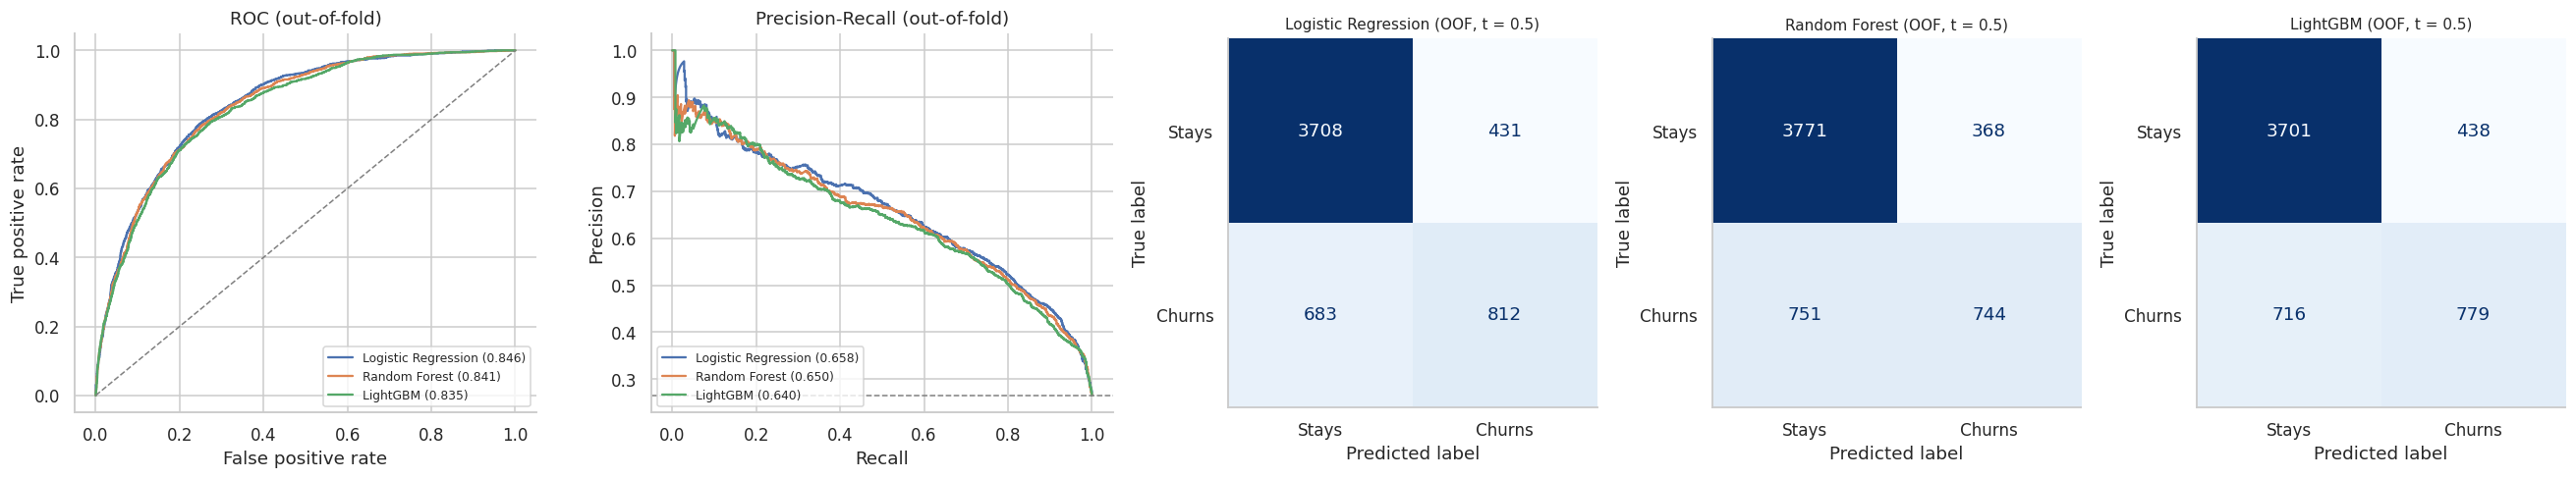

In [19]:
candidates = ["Logistic Regression", "Random Forest", "LightGBM"]
fig, axes = plt.subplots(1, 5, figsize=(24, 4.6), gridspec_kw={"width_ratios": [1.25, 1.25, 1, 1, 1]})
for name in candidates:
    fpr, tpr, _ = roc_curve(y_train, oof_proba[name])
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_train, oof_proba[name]):.3f})")
    prec, rec, _ = precision_recall_curve(y_train, oof_proba[name])
    axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_train, oof_proba[name]):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (out-of-fold)")
axes[1].axhline(base_rate, color="gray", ls="--", lw=1)
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (out-of-fold)")
for ax in axes[:2]:
    ax.legend(fontsize=8, loc="lower left" if ax is axes[1] else "lower right")
for ax, name in zip(axes[2:], candidates):
    ConfusionMatrixDisplay.from_predictions(y_train, (oof_proba[name] >= 0.5).astype(int),
                                            display_labels=["Stays", "Churns"], cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{name} (OOF, t = 0.5)", fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.show()

**Findings.**

- All models are far above the Dummy baseline (PR-AUC 0.27, ROC-AUC 0.51).
- **Logistic Regression** has the best default PR-AUC (0.661) and ROC-AUC (0.846), slightly ahead of
  Random Forest (0.653) and default LightGBM (0.643). The gaps are within one standard deviation
  across folds (≈ 0.02): the problem is close to linear in its main signals.
- At threshold 0.5 all models miss about half of the churners (recall 0.50-0.54): the threshold,
  not the model family, is the main lever for recall (Section 8).
- The ROC and precision-recall curves overlap almost completely.

**Initial selection.** Logistic Regression is the strongest default and the reference to beat.
LightGBM is selected for optimization because it has the richest hyperparameter space, is the
model most likely to gain from tuning (its default is under-regularized), captures the contract ×
internet interaction found in the EDA, and supports exact TreeSHAP. If tuning cannot beat Logistic
Regression, the simpler model should be preferred.

**Most relevant metrics.** PR-AUC to compare ranking quality on the churn class; recall and
precision at the chosen threshold to size a campaign; ROC-AUC as a secondary ranking metric.

## 6. Hyperparameter Optimization (LightGBM)

### 6.1 Experimental protocol

Every strategy evaluates configurations with the **same objective**: mean PR-AUC over the same
5 folds, with the full pipeline refitted inside each fold. All strategies are run through Optuna so
that only the sampler changes; `GridSampler` evaluates exactly the Cartesian grid (as
`GridSearchCV`), `RandomSampler` draws independent samples (as `RandomizedSearchCV`).

| Strategy | How it works | Budget |
|:--|:--|:--|
| Grid Search | Exhaustive evaluation of a fixed Cartesian grid. Simple and reproducible, but the cost grows exponentially and only listed values are explored. | 48 (full grid) |
| Random Search | Independent samples from the full space. Covers important dimensions better than a grid for the same budget. | 48 per seed |
| TPE (Bayesian) | Splits past trials into good and bad groups, models each with a density, and samples where the ratio good/bad is highest. Learns from previous trials. | 48 per seed |
| NSGA-II | Evolutionary multi-objective search (Section 7). | 48 |

Random and TPE are stochastic: each is run with **3 seeds** to separate method from luck.

In [20]:
N_TRIALS = 48
SEEDS = [42, 7, 2026]

SEARCH_SPACE = pd.DataFrame([
    ("n_estimators", "int", "100 - 600", "linear", "[150, 400]"),
    ("learning_rate", "float", "0.01 - 0.2", "log", "[0.03, 0.1]"),
    ("num_leaves", "int", "8 - 64", "linear", "[8, 16, 32]"),
    ("min_child_samples", "int", "10 - 100", "linear", "[20, 60]"),
    ("colsample_bytree", "float", "0.6 - 1.0", "linear", "[0.6, 0.9]"),
    ("subsample", "float", "0.6 - 1.0", "linear", "fixed 1.0"),
    ("reg_lambda", "float", "0.001 - 10", "log", "fixed 0.0"),
], columns=["hyperparameter", "type", "range (Random, TPE, NSGA-II)", "scale", "Grid values"]).set_index("hyperparameter")
SEARCH_SPACE

,type,"range (Random, TPE, NSGA-II)",scale,Grid values
hyperparameter,,,,
n_estimators,int,100 - 600,linear,"[150, 400]"
learning_rate,float,0.01 - 0.2,log,"[0.03, 0.1]"
num_leaves,int,8 - 64,linear,"[8, 16, 32]"
min_child_samples,int,10 - 100,linear,"[20, 60]"
colsample_bytree,float,0.6 - 1.0,linear,"[0.6, 0.9]"
subsample,float,0.6 - 1.0,linear,fixed 1.0
reg_lambda,float,0.001 - 10,log,fixed 0.0


`num_leaves` and `min_child_samples` control tree complexity; `learning_rate` and `n_estimators`
the boosting trajectory; `subsample`, `colsample_bytree` and `reg_lambda` add regularization.

In [21]:
GRID = {
    "n_estimators": [150, 400],
    "learning_rate": [0.03, 0.1],
    "num_leaves": [8, 16, 32],
    "min_child_samples": [20, 60],
    "colsample_bytree": [0.6, 0.9],
}


def make_lgbm(params):
    return LGBMClassifier(**BASE_LGBM, **params)


def total_leaves(pipeline):
    trees = pipeline.named_steps["model"].booster_.dump_model()["tree_info"]
    return sum(t["num_leaves"] for t in trees)


def evaluate_config(params, with_complexity=False):
    res = cross_validate(make_pipeline(make_lgbm(params)), X_train, y_train, cv=CV_SPLITS,
                         scoring="average_precision", n_jobs=N_JOBS, return_estimator=with_complexity)
    out = {"pr_auc": res["test_score"].mean(), "pr_auc_std": res["test_score"].std(ddof=1)}
    if with_complexity:
        out["total_leaves"] = float(np.mean([total_leaves(e) for e in res["estimator"]]))
    return out


def suggest_full_space(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 64),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }


def objective_full(trial):
    result = evaluate_config(suggest_full_space(trial))
    trial.set_user_attr("pr_auc_std", result["pr_auc_std"])
    return result["pr_auc"]


def objective_grid(trial):
    params = {k: trial.suggest_categorical(k, v) for k, v in GRID.items()}
    result = evaluate_config(params)
    trial.set_user_attr("pr_auc_std", result["pr_auc_std"])
    return result["pr_auc"]


def run_study(strategy, seed, sampler, objective, n_trials=N_TRIALS):
    study = optuna.create_study(direction="maximize", sampler=sampler, study_name=f"{strategy}_{seed}")
    start = time.perf_counter()
    study.optimize(objective, n_trials=n_trials)
    elapsed = time.perf_counter() - start
    trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "duration"))
    trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in trials.columns]
    trials["strategy"], trials["seed"] = strategy, seed
    trials["evaluation"] = trials["number"] + 1
    trials["elapsed_s"] = trials["duration"].dt.total_seconds().cumsum()
    trials["best_so_far"] = trials["value"].cummax()
    return study, trials.drop(columns="duration"), elapsed

In [22]:
studies, trial_tables, run_rows = {}, [], []

study, trials, elapsed = run_study("Grid", SEED, optuna.samplers.GridSampler(GRID, seed=SEED), objective_grid,
                                   n_trials=int(np.prod([len(v) for v in GRID.values()])))
studies[("Grid", SEED)] = study
trial_tables.append(trials)
run_rows.append({"strategy": "Grid", "seed": SEED, "time_s": elapsed, "n_configs": len(trials)})

for seed in SEEDS:
    for strategy, sampler in [("Random", optuna.samplers.RandomSampler(seed=seed)),
                              ("TPE", optuna.samplers.TPESampler(seed=seed))]:
        study, trials, elapsed = run_study(strategy, seed, sampler, objective_full)
        studies[(strategy, seed)] = study
        trial_tables.append(trials)
        run_rows.append({"strategy": strategy, "seed": seed, "time_s": elapsed, "n_configs": len(trials)})

hpo_trials = pd.concat(trial_tables, ignore_index=True)
hpo_runs = pd.DataFrame(run_rows)
hpo_runs["best_pr_auc"] = [studies[(r.strategy, r.seed)].best_value for r in hpo_runs.itertuples()]
hpo_runs

,strategy,seed,time_s,n_configs,best_pr_auc
0,Grid,42,88.0423,48,0.6673
1,Random,42,142.6913,48,0.6696
2,TPE,42,98.9114,48,0.6687
3,Random,7,142.9036,48,0.6699
4,TPE,7,82.2827,48,0.6695
5,Random,2026,139.1018,48,0.6680
6,TPE,2026,84.3708,48,0.6681


### 6.2 Results

In [23]:
def evaluations_to_reach(trials, target):
    hit = trials.loc[trials["best_so_far"] >= target, "evaluation"]
    return hit.iloc[0] if len(hit) else np.nan

global_best = hpo_trials["value"].max()
TARGET_SHARE = 0.995
hpo_runs["evals_to_99.5pct_best"] = [
    evaluations_to_reach(hpo_trials[(hpo_trials.strategy == r.strategy) & (hpo_trials.seed == r.seed)],
                         TARGET_SHARE * global_best)
    for r in hpo_runs.itertuples()]

hpo_summary = hpo_runs.groupby("strategy", sort=False).agg(
    runs=("seed", "size"),
    configs_per_run=("n_configs", "first"),
    best_pr_auc_mean=("best_pr_auc", "mean"),
    best_pr_auc_std=("best_pr_auc", "std"),
    time_s_mean=("time_s", "mean"),
    time_s_std=("time_s", "std"),
    evals_to_near_best=("evals_to_99.5pct_best", "mean"),
)
hpo_summary

,runs,configs_per_run,best_pr_auc_mean,best_pr_auc_std,time_s_mean,time_s_std,evals_to_near_best
strategy,,,,,,,
Grid,1,48,0.6673,NaN,88.0423,NaN,13.0000
Random,3,48,0.6692,0.0010,141.5656,2.1363,8.6667
TPE,3,48,0.6688,0.0007,88.5216,9.0582,10.3333


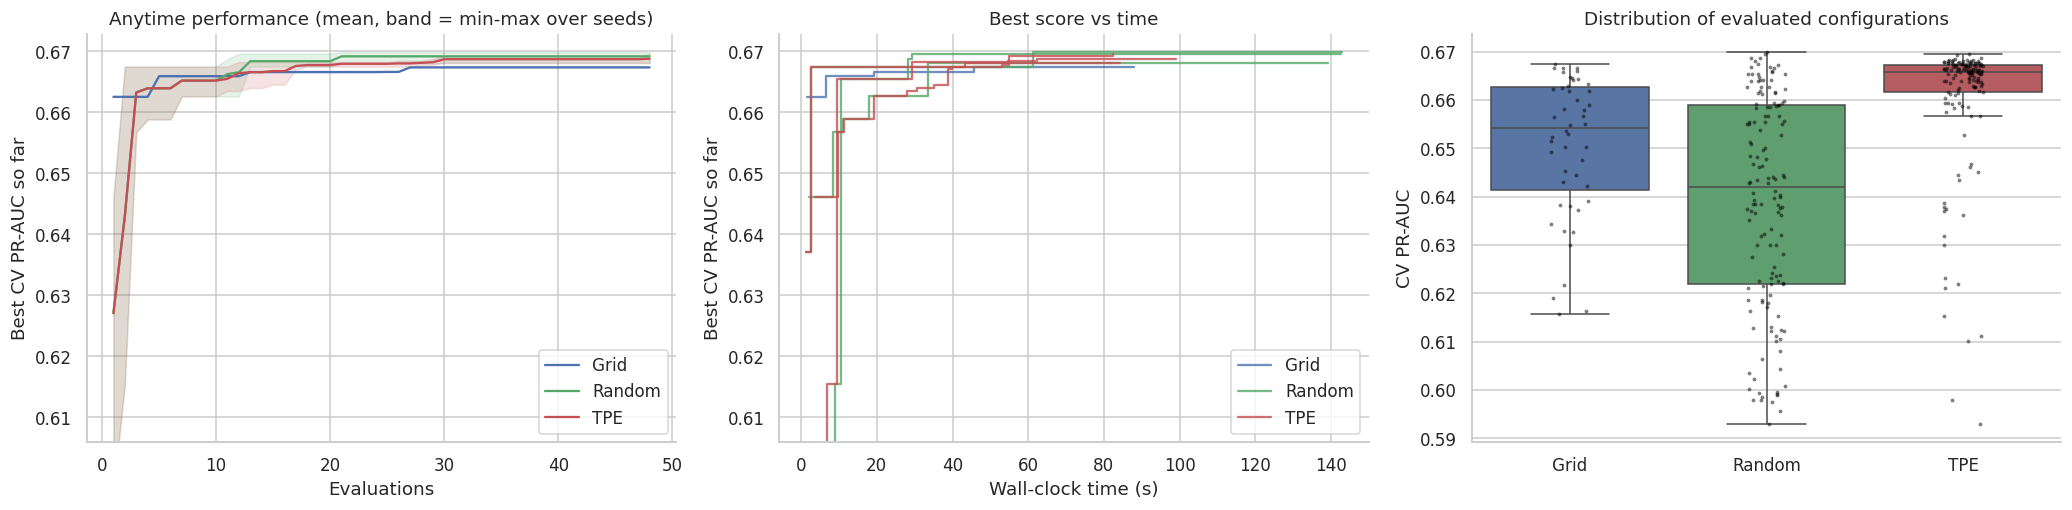

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for strategy, group in hpo_trials.groupby("strategy", sort=False):
    curves = group.pivot(index="evaluation", columns="seed", values="best_so_far")
    mean, low, high = curves.mean(axis=1), curves.min(axis=1), curves.max(axis=1)
    axes[0].plot(mean.index, mean, color=STRATEGY_COLORS[strategy], label=strategy)
    axes[0].fill_between(mean.index, low, high, color=STRATEGY_COLORS[strategy], alpha=0.15)
    time_curve = group.groupby("seed")
    for k, (_, run) in enumerate(time_curve):
        axes[1].step(run["elapsed_s"], run["best_so_far"], where="post", color=STRATEGY_COLORS[strategy],
                     alpha=0.8, label=strategy if k == 0 else None)
axes[0].set(xlabel="Evaluations", ylabel="Best CV PR-AUC so far",
            title="Anytime performance (mean, band = min-max over seeds)")
axes[1].set(xlabel="Wall-clock time (s)", ylabel="Best CV PR-AUC so far", title="Best score vs time")
lower = hpo_trials["value"].quantile(0.05)
for ax in axes[:2]:
    ax.set_ylim(lower, global_best + 0.003)
    ax.legend()

sns.boxplot(data=hpo_trials, x="strategy", y="value", hue="strategy", palette=STRATEGY_COLORS, ax=axes[2],
            legend=False, fliersize=0)
sns.stripplot(data=hpo_trials, x="strategy", y="value", color="black", size=2.5, alpha=0.5, ax=axes[2])
axes[2].set(xlabel="", ylabel="CV PR-AUC", title="Distribution of evaluated configurations")
plt.tight_layout()
plt.show()

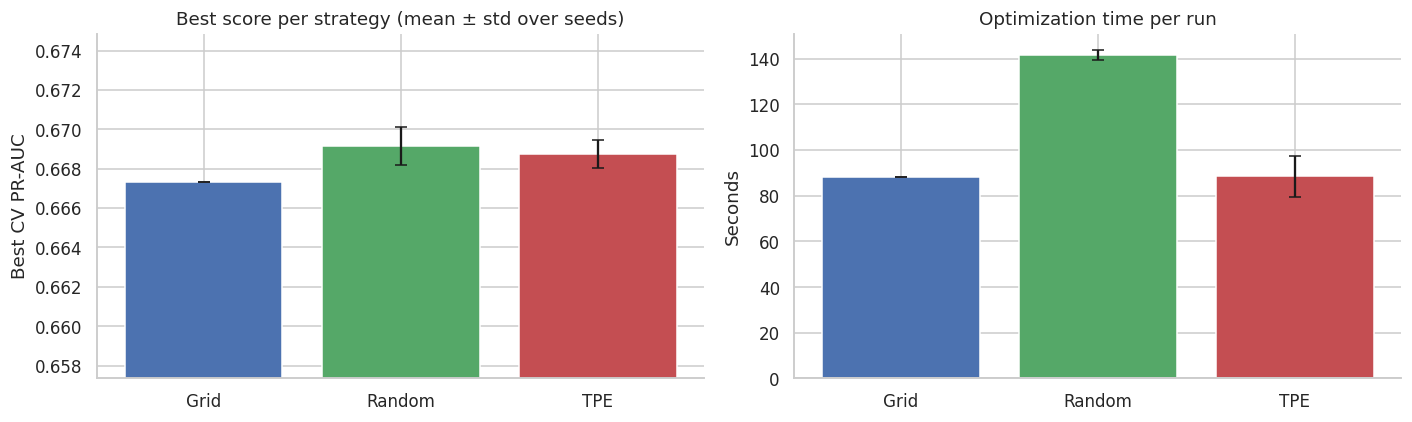

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = hpo_summary.index
axes[0].bar(order, hpo_summary["best_pr_auc_mean"], yerr=hpo_summary["best_pr_auc_std"].fillna(0),
            color=[STRATEGY_COLORS[s] for s in order], capsize=4)
axes[0].set_ylim(hpo_summary["best_pr_auc_mean"].min() - 0.01, global_best + 0.005)
axes[0].set(ylabel="Best CV PR-AUC", title="Best score per strategy (mean ± std over seeds)")
axes[1].bar(order, hpo_summary["time_s_mean"], yerr=hpo_summary["time_s_std"].fillna(0),
            color=[STRATEGY_COLORS[s] for s in order], capsize=4)
axes[1].set(ylabel="Seconds", title="Optimization time per run")
plt.tight_layout()
plt.show()

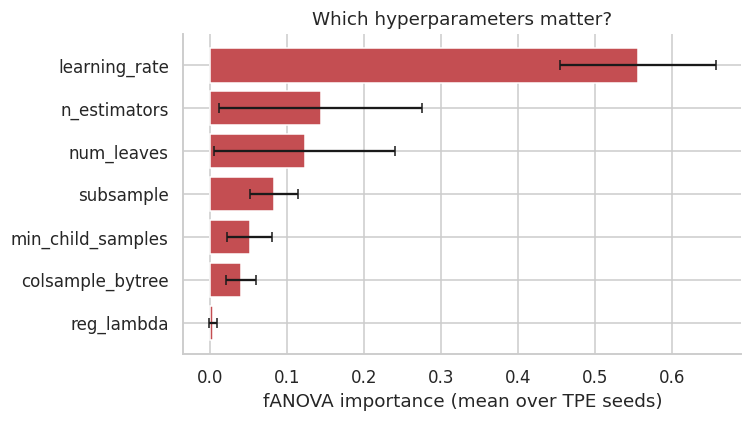

In [26]:
tpe_importance = pd.DataFrame({
    f"seed {seed}": optuna.importance.get_param_importances(studies[("TPE", seed)], evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
    for seed in SEEDS
}).fillna(0)
tpe_importance = tpe_importance.loc[tpe_importance.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(tpe_importance.index, tpe_importance.mean(axis=1), xerr=tpe_importance.std(axis=1), color="#C44E52", capsize=3)
ax.set(xlabel="fANOVA importance (mean over TPE seeds)", title="Which hyperparameters matter?")
plt.tight_layout()
plt.show()

**Findings.**

- **Performance:** all strategies reach PR-AUC ≈ 0.667-0.670 (Random 0.6692 ± 0.0010, TPE 0.6688 ±
  0.0007, Grid 0.6673). The differences (≤ 0.002) are far smaller than the fold-to-fold standard
  error (≈ 0.01): **the optimizers are statistically tied** on this problem.
- **Anytime performance:** all strategies reach 99.5 % of the best score within 9-13 evaluations.
  The search landscape has a broad plateau, so a modest budget is enough.
- **Time:** TPE is ≈ 38 % faster than Random for the same 48 evaluations (≈ 89 s vs 142 s) and as fast as Grid. Random
  samples expensive configurations (many trees, many leaves) uniformly; TPE learns that they do not
  pay off and concentrates on cheaper, better ones.
- **Distribution:** TPE's evaluations cluster near the top (tight box), Random's spread widely and
  Grid sits in between. TPE wastes fewer evaluations on poor regions.
- **Hyperparameter importance:** `learning_rate` explains most of the variance (≈ 55 %), followed by
  `n_estimators` and `num_leaves`. `reg_lambda` is irrelevant. The interaction learning rate ×
  number of trees is what matters: slow learning with a moderate number of small trees works best.

**Advantages and limitations.**

| Strategy | Advantages | Limitations |
|:--|:--|:--|
| Grid | Reproducible, easy to explain, no randomness | Only listed values; cost grows exponentially; could not tune `subsample` or `reg_lambda` within 48 evaluations |
| Random | Explores all 7 dimensions; trivially parallel | Wastes time on poor and expensive regions; result depends on the seed |
| TPE | Learns from history, concentrates on good regions, fastest here | Sequential by nature; needs a few random start-up trials |

### 6.3 Full metrics of each strategy's best configuration

The best configuration found by each strategy (best seed) is re-evaluated with all metrics on the
same folds.

In [27]:
best_configs = {}
for strategy in ["Grid", "Random", "TPE"]:
    runs = {seed: s for (st, seed), s in studies.items() if st == strategy}
    best_study = max(runs.values(), key=lambda s: s.best_value)
    best_configs[strategy] = best_study.best_params

strategy_rows = []
for strategy, params in best_configs.items():
    res = cross_validate(make_pipeline(make_lgbm(params)), X_train, y_train, cv=CV_SPLITS, scoring=SCORING,
                         n_jobs=N_JOBS)
    strategy_rows.append({"strategy": strategy, **{m: res[f"test_{m}"].mean() for m in SCORING},
                          "pr_auc_std": res["test_pr_auc"].std(ddof=1),
                          "time_s_mean": hpo_summary.loc[strategy, "time_s_mean"],
                          "configs_evaluated": hpo_summary.loc[strategy, "configs_per_run"]})
default_row = model_comparison.loc["LightGBM"]
strategy_rows.insert(0, {"strategy": "Default LightGBM", **{m: default_row[m] for m in SCORING},
                         "pr_auc_std": default_row["pr_auc_std"], "time_s_mean": 0.0, "configs_evaluated": 1})
strategy_comparison = pd.DataFrame(strategy_rows).set_index("strategy")
display(strategy_comparison)
pd.DataFrame(best_configs).T

,accuracy,precision,recall,f1,roc_auc,pr_auc,pr_auc_std,time_s_mean,configs_evaluated
strategy,,,,,,,,,
Default LightGBM,0.7952,0.6408,0.5211,0.5746,0.8349,0.6428,0.0233,0.0000,1
Grid,0.8071,0.6791,0.5197,0.5884,0.8490,0.6673,0.0215,88.0423,48
Random,0.8037,0.6643,0.5278,0.5877,0.8489,0.6699,0.0213,141.5656,48
TPE,0.8056,0.6739,0.5197,0.5867,0.8498,0.6695,0.0236,88.5216,48


,n_estimators,learning_rate,num_leaves,min_child_samples,colsample_bytree,subsample,reg_lambda
Grid,150.0000,0.0300,8.0000,60.0000,0.9000,NaN,NaN
Random,375.0000,0.0164,10.0000,35.0000,0.9231,0.6179,0.0011
TPE,190.0000,0.0213,11.0000,83.0000,0.8050,0.6332,0.0294


**Findings and selected strategy.** All tuned configurations improve the default LightGBM (PR-AUC
0.643 → 0.667-0.670, ROC-AUC 0.835 → 0.849-0.850), mainly by slowing the learning rate and using
small trees (8-11 leaves). Tuned LightGBM now exceeds Logistic
Regression (0.661), although by less than one standard error.

**Selected strategy: TPE.** Its quality equals the best, it has the lowest variance across seeds,
it is the fastest for the same budget, and it scales to larger spaces where a grid becomes
impossible. Random Search is a valid alternative when trials can be fully parallelized.

## 7. Multi-objective Optimization (NSGA-II)

### 7.1 Formulation

For a configuration $\theta$ in the same search space:

$$
\max_{\theta} \; f_1(\theta) = \frac{1}{K}\sum_{k=1}^{K} \mathrm{PR\text{-}AUC}_k(\theta)
\qquad
\min_{\theta} \; f_2(\theta) = \frac{1}{K}\sum_{k=1}^{K} \sum_{t=1}^{T} L_{t,k}(\theta)
$$

where $L_{t,k}$ is the number of leaves of tree $t$ in fold $k$. $f_2$ is the model complexity:
it drives inference time, memory and auditability, and unlike measured latency it is
deterministic and hardware independent. Latency is measured afterwards for the Pareto solutions.

**Business link:** scoring the full customer base daily and serving real-time scores to call-center
agents favors small models, as long as ranking quality is not sacrificed.

NSGA-II evolves a population (16 individuals, 3 generations, 48 evaluations) using non-dominated
sorting and crowding distance to keep a diverse front.

In [28]:
def objective_multi(trial):
    result = evaluate_config(suggest_full_space(trial), with_complexity=True)
    trial.set_user_attr("pr_auc_std", result["pr_auc_std"])
    return result["pr_auc"], result["total_leaves"]


mo_study = optuna.create_study(directions=["maximize", "minimize"],
                               sampler=optuna.samplers.NSGAIISampler(population_size=16, seed=SEED),
                               study_name="nsga2")
start = time.perf_counter()
mo_study.optimize(objective_multi, n_trials=N_TRIALS)
mo_time = time.perf_counter() - start

pareto_ids = {t.number for t in mo_study.best_trials}
mo_trials = pd.DataFrame([{
    "trial": t.number, "pr_auc": t.values[0], "total_leaves": t.values[1],
    "pr_auc_std": t.user_attrs["pr_auc_std"], "pareto": t.number in pareto_ids, **t.params,
} for t in mo_study.trials if t.state == optuna.trial.TrialState.COMPLETE])

Markdown(f"NSGA-II: {len(mo_trials)} configurations in {mo_time:.0f} s; "
         f"**{len(pareto_ids)} non-dominated solutions**.")

NSGA-II: 48 configurations in 157 s; **4 non-dominated solutions**.

### 7.2 Selection rule: one-standard-error

The best PR-AUC observed across **all** optimizers is the reference. Any configuration whose mean
PR-AUC is within one standard error ($SE = s / \sqrt{K}$) of it is statistically indistinguishable.
Among those, the Pareto solution with the **lowest complexity** is selected. The knee point
(largest distance to the line joining the extremes of the front) is shown for comparison.

In [29]:
all_single = hpo_trials.dropna(subset=["value"])
ref = all_single.loc[all_single["value"].idxmax()]
ref_pr_auc = max(ref["value"], mo_trials["pr_auc"].max())
ref_std = ref["pr_auc_std"] if ref["value"] >= mo_trials["pr_auc"].max() else \
    mo_trials.loc[mo_trials["pr_auc"].idxmax(), "pr_auc_std"]
one_se_threshold = ref_pr_auc - ref_std / np.sqrt(N_FOLDS)

pareto = mo_trials[mo_trials["pareto"]].sort_values("total_leaves").reset_index(drop=True)
eligible = pareto[pareto["pr_auc"] >= one_se_threshold]
selected = eligible.iloc[0] if len(eligible) else pareto.loc[pareto["pr_auc"].idxmax()]

norm = (pareto[["total_leaves", "pr_auc"]] - pareto[["total_leaves", "pr_auc"]].min()) / \
       (pareto[["total_leaves", "pr_auc"]].max() - pareto[["total_leaves", "pr_auc"]].min())
p1, p2 = norm.iloc[0].to_numpy(), norm.iloc[-1].to_numpy()
pts = norm.to_numpy()
distance = np.abs((p2[0] - p1[0]) * (p1[1] - pts[:, 1]) - (p1[0] - pts[:, 0]) * (p2[1] - p1[1])) / np.linalg.norm(p2 - p1)
knee = pareto.iloc[int(np.argmax(distance))]

display(pareto[["trial", "pr_auc", "pr_auc_std", "total_leaves", "n_estimators", "num_leaves",
                "learning_rate", "min_child_samples"]])
Markdown(f"Reference PR-AUC {ref_pr_auc:.4f}; 1-SE threshold **{one_se_threshold:.4f}**. "
         f"Selected trial **{int(selected.trial)}** (PR-AUC {selected.pr_auc:.4f}, "
         f"{selected.total_leaves:.0f} leaves). Knee point: trial {int(knee.trial)}.")

,trial,pr_auc,pr_auc_std,total_leaves,n_estimators,num_leaves,learning_rate,min_child_samples
0,36,0.6650,0.0212,896.0000,112,8,0.0293,88
1,17,0.6657,0.0222,1440.0000,144,10,0.0180,83
2,31,0.6661,0.0242,1566.8000,112,14,0.0293,88
3,11,0.6696,0.0230,1918.0000,137,14,0.0293,88


Reference PR-AUC 0.6699; 1-SE threshold **0.6603**. Selected trial **36** (PR-AUC 0.6650, 896 leaves). Knee point: trial 31.

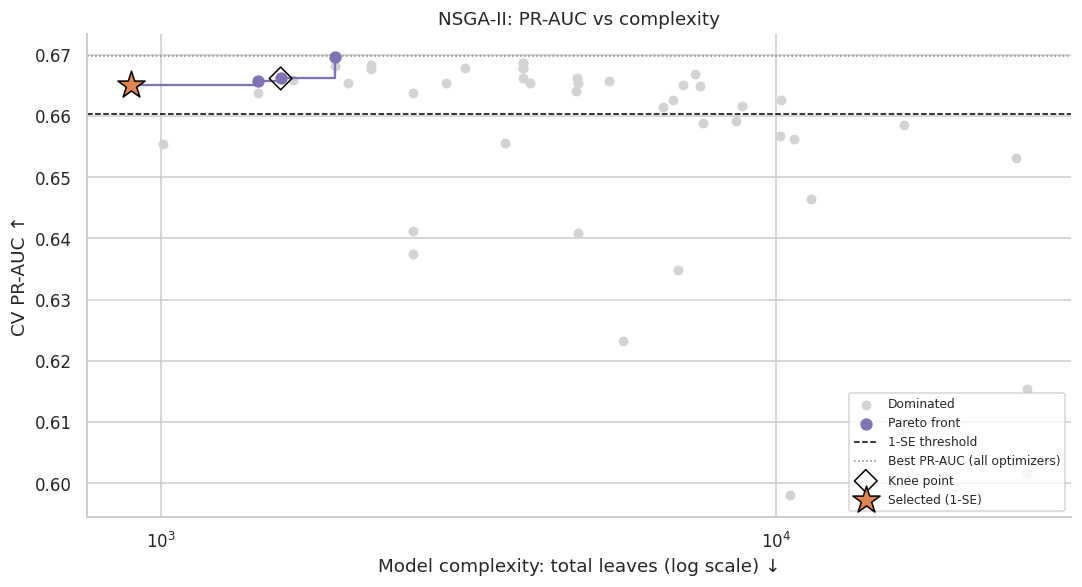

In [30]:
fig, ax = plt.subplots(figsize=(10, 5.5))
dominated = mo_trials[~mo_trials["pareto"]]
ax.scatter(dominated["total_leaves"], dominated["pr_auc"], color="lightgray", s=30, label="Dominated")
ax.step(pareto["total_leaves"], pareto["pr_auc"], where="post", color=STRATEGY_COLORS["NSGA-II"], lw=1.5)
ax.scatter(pareto["total_leaves"], pareto["pr_auc"], color=STRATEGY_COLORS["NSGA-II"], s=50, zorder=3,
           label="Pareto front")
ax.axhline(one_se_threshold, color="black", ls="--", lw=1, label="1-SE threshold")
ax.axhline(ref_pr_auc, color="gray", ls=":", lw=1, label="Best PR-AUC (all optimizers)")
ax.scatter(knee["total_leaves"], knee["pr_auc"], marker="D", s=110, facecolors="none", edgecolors="black",
           zorder=4, label="Knee point")
ax.scatter(selected["total_leaves"], selected["pr_auc"], marker="*", s=350, color="#DD8452",
           edgecolors="black", zorder=5, label="Selected (1-SE)")
ax.set_xscale("log")
ax.set(xlabel="Model complexity: total leaves (log scale) ↓", ylabel="CV PR-AUC ↑",
       title="NSGA-II: PR-AUC vs complexity")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### 7.3 Measured inference latency of the Pareto solutions

,trial,total_leaves,pr_auc,ms_per_1000_customers
0,36,896.0000,0.6650,16.4005
1,17,1440.0000,0.6657,19.5455
2,31,1566.8000,0.6661,17.4694
3,11,1918.0000,0.6696,21.1026


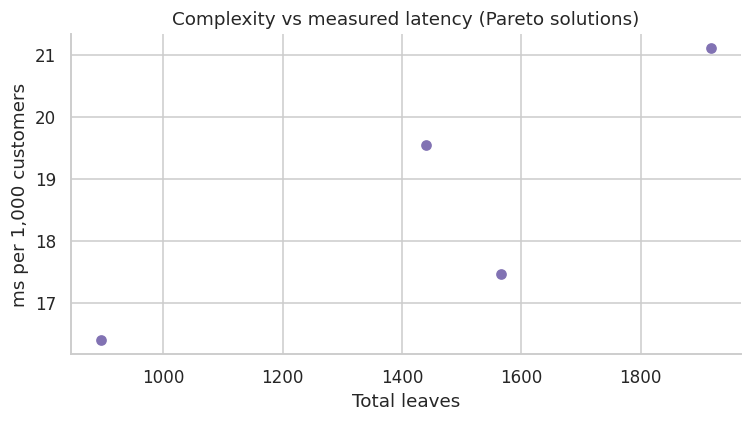

Spearman correlation complexity-latency: **0.80**

In [31]:
def measure_latency(pipeline, data, repeats=7):
    pipeline.predict_proba(data)
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        pipeline.predict_proba(data)
        times.append(time.perf_counter() - start)
    return 1000 * np.median(times) / len(data) * 1000


param_cols = ["n_estimators", "learning_rate", "num_leaves", "min_child_samples", "colsample_bytree",
              "subsample", "reg_lambda"]
latency_rows = []
for row in pareto.itertuples():
    params = {p: getattr(row, p) for p in param_cols}
    params["n_estimators"], params["num_leaves"], params["min_child_samples"] = \
        int(params["n_estimators"]), int(params["num_leaves"]), int(params["min_child_samples"])
    fitted = make_pipeline(make_lgbm(params)).fit(X_train, y_train)
    latency_rows.append({"trial": row.trial, "total_leaves": row.total_leaves, "pr_auc": row.pr_auc,
                         "ms_per_1000_customers": measure_latency(fitted, X_train)})
pareto_latency = pd.DataFrame(latency_rows)
display(pareto_latency)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(pareto_latency["total_leaves"], pareto_latency["ms_per_1000_customers"], color=STRATEGY_COLORS["NSGA-II"])
ax.set(xlabel="Total leaves", ylabel="ms per 1,000 customers", title="Complexity vs measured latency (Pareto solutions)")
plt.tight_layout()
plt.show()
Markdown(f"Spearman correlation complexity-latency: **{stats.spearmanr(pareto_latency.total_leaves, pareto_latency.ms_per_1000_customers)[0]:.2f}**")

**Findings.**

- NSGA-II found 4 non-dominated solutions, from 896 to 1,918 total leaves. Larger models in the
  population (up to tens of thousands of leaves) are all dominated: extra complexity does not buy
  ranking quality.
- **Trade-off:** going from the most accurate Pareto model (PR-AUC 0.6696, 1,918 leaves) to the
  simplest (0.6650, 896 leaves) costs 0.005 PR-AUC, half a standard error, for 53 % fewer leaves.
- **1-SE selection:** the threshold is 0.6603, so the simplest Pareto solution, **trial 36**
  (112 trees × 8 leaves), qualifies. The knee point (trial 31) has more leaves for no significant gain.
- **Latency:** complexity and measured latency are correlated (Spearman 0.80), confirming the proxy.
  In absolute terms all Pareto models score 1,000 customers in about 16-21 ms, so the benefit of the
  small model is mostly lower maintenance and easier audit, not raw speed.

**Why prefer one Pareto solution over another.** Technically, a model that is statistically as
good but simpler generalizes more reliably and is cheaper to monitor and explain. For the
business, a retention team scoring the whole base daily or serving real-time scores in a call
center benefits from the small model. A company that only scores a few thousand customers once a
month could choose the most accurate end of the front instead; the front makes that choice explicit.

### 7.4 Optimizer comparison including NSGA-II

In [32]:
nsga_row = {"strategy": "NSGA-II", "runs": 1, "configs_per_run": len(mo_trials),
            "best_pr_auc_mean": mo_trials["pr_auc"].max(), "best_pr_auc_std": np.nan,
            "time_s_mean": mo_time, "time_s_std": np.nan, "evals_to_near_best": np.nan}
optimizer_table = pd.concat([hpo_summary, pd.DataFrame([nsga_row]).set_index("strategy")])
optimizer_table["objectives"] = ["PR-AUC (grid of 5 params)", "PR-AUC", "PR-AUC", "PR-AUC + complexity"]
optimizer_table

,runs,configs_per_run,best_pr_auc_mean,best_pr_auc_std,time_s_mean,time_s_std,evals_to_near_best,objectives
strategy,,,,,,,,
Grid,1,48,0.6673,NaN,88.0423,NaN,13.0000,PR-AUC (grid of 5 params)
Random,3,48,0.6692,0.0010,141.5656,2.1363,8.6667,PR-AUC
TPE,3,48,0.6688,0.0007,88.5216,9.0582,10.3333,PR-AUC
NSGA-II,1,48,0.6696,NaN,157.0391,NaN,NaN,PR-AUC + complexity


### 7.5 Final model configuration

The selected configuration is the 1-SE solution of the Pareto front. Its full metrics are compared
with the best single-objective configuration.

In [33]:
FINAL_PARAMS = {p: selected[p] for p in param_cols}
for p in ["n_estimators", "num_leaves", "min_child_samples"]:
    FINAL_PARAMS[p] = int(FINAL_PARAMS[p])

best_single_strategy = strategy_comparison.drop(index="Default LightGBM")["pr_auc"].idxmax()
final_candidates = {f"Best single-objective ({best_single_strategy})": best_configs[best_single_strategy],
                    "Selected: NSGA-II 1-SE": FINAL_PARAMS}
rows = []
for name, params in final_candidates.items():
    res = cross_validate(make_pipeline(make_lgbm(params)), X_train, y_train, cv=CV_SPLITS, scoring=SCORING,
                         n_jobs=N_JOBS, return_estimator=True)
    rows.append({"candidate": name, **{m: res[f"test_{m}"].mean() for m in SCORING},
                 "total_leaves": np.mean([total_leaves(e) for e in res["estimator"]])})
final_comparison = pd.DataFrame(rows).set_index("candidate")
display(final_comparison)
pd.Series(FINAL_PARAMS, name="value").to_frame()

,accuracy,precision,recall,f1,roc_auc,pr_auc,total_leaves
candidate,,,,,,,
Best single-objective (Random),0.8037,0.6643,0.5278,0.5877,0.8489,0.6699,3750.0000
Selected: NSGA-II 1-SE,0.8051,0.6794,0.5057,0.5795,0.8490,0.6650,896.0000


,value
n_estimators,112.0000
learning_rate,0.0293
num_leaves,8.0000
min_child_samples,88.0000
colsample_bytree,0.8827
subsample,0.6888
reg_lambda,4.2684


**Final model.** The selected configuration matches the best single-objective model in ROC-AUC
(0.849) and accuracy (0.805), trails it by 0.005 in PR-AUC (within noise), and uses **76 % fewer
leaves** (896 vs 3,750). It is also strongly regularized (`reg_lambda` ≈ 4.3, `min_child_samples` 88),
which favors stable explanations.

## 8. Decision Threshold and Calibration

All analyses here use **out-of-fold** probabilities on the training set. Test is still unused.

### 8.1 Calibration

The app shows churn probabilities, so they must be trustworthy.

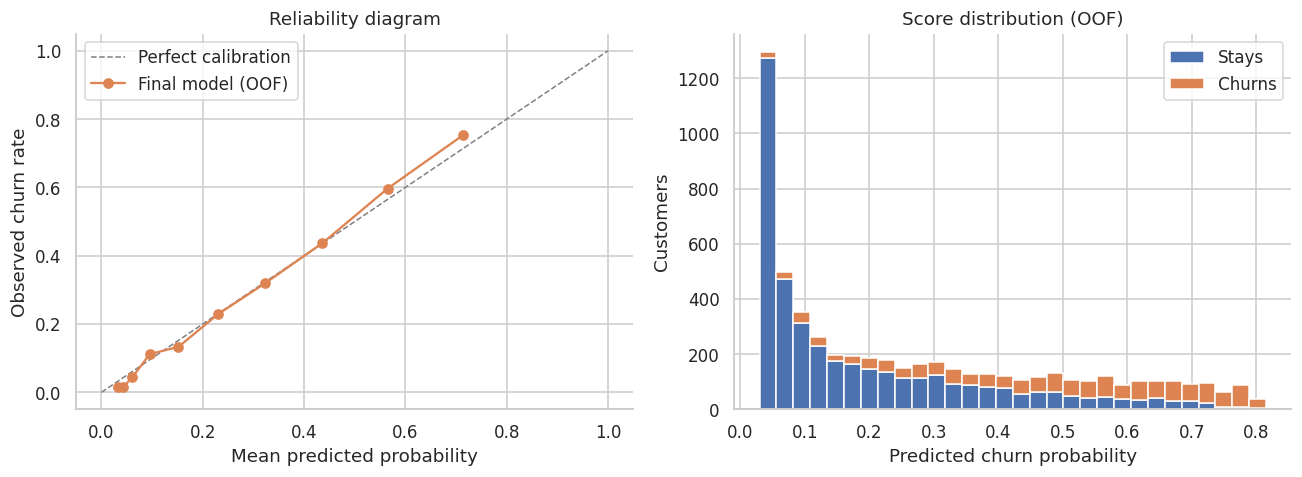

,value
brier_score,0.1345
brier_reference (predict base rate),0.1949
expected_calibration_error,0.0176


In [34]:
final_pipeline = make_pipeline(make_lgbm(FINAL_PARAMS))
oof_final = cross_val_predict(final_pipeline, X_train, y_train, cv=CV_SPLITS, method="predict_proba",
                              n_jobs=N_JOBS)[:, 1]

frac_pos, mean_pred = calibration_curve(y_train, oof_final, n_bins=10, strategy="quantile")
bins = pd.qcut(oof_final, 10, duplicates="drop")
ece = (pd.DataFrame({"p": oof_final, "y": y_train.to_numpy(), "bin": bins})
       .groupby("bin", observed=True).apply(lambda g: len(g) * abs(g.p.mean() - g.y.mean()), include_groups=False).sum()
       / len(oof_final))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="Perfect calibration")
axes[0].plot(mean_pred, frac_pos, marker="o", color="#DD8452", label="Final model (OOF)")
axes[0].set(xlabel="Mean predicted probability", ylabel="Observed churn rate", title="Reliability diagram")
axes[0].legend()
axes[1].hist([oof_final[y_train == 0], oof_final[y_train == 1]], bins=30, stacked=True,
             color=[CHURN_COLORS[0], CHURN_COLORS[1]], label=["Stays", "Churns"])
axes[1].set(xlabel="Predicted churn probability", ylabel="Customers", title="Score distribution (OOF)")
axes[1].legend()
plt.tight_layout()
plt.show()

pd.Series({"brier_score": brier_score_loss(y_train, oof_final),
           "brier_reference (predict base rate)": brier_score_loss(y_train, np.full(len(y_train), base_rate)),
           "expected_calibration_error": ece}, name="value").to_frame()

**Findings.** The reliability curve follows the diagonal (expected calibration error 0.018) and
the Brier score (0.135) is well below the reference of always predicting the base rate (0.195).
**No calibration step is needed**: the probabilities shown in the app can be read as churn rates
("of 100 customers with 30 % risk, about 30 churn"). Most customers receive low scores; churners
spread over the upper range.

### 8.2 Business cost model (hypothetical, declared)

The values below are **assumptions** for a retention campaign, not data from the dataset. They are
editable here and in the Streamlit app.

| Parameter | Value | Justification |
|:--|:--|:--|
| Retention horizon | 12 months | Typical annual planning horizon for customer value |
| Gross margin | 50 % | Conservative margin on monthly revenue for a telecom operator |
| Contact + incentive cost | USD 40 | Call-center contact plus an average discount offer |
| Retention success rate | 30 % | Share of contacted churners who accept the offer and stay |

Value of a retained customer $i$: $V_i = \text{MonthlyCharges}_i \times 12 \times 0.5$.

Expected profit when contacting the set $S_t = \{i : \hat p_i \ge t\}$:

$$
\Pi(t) = \sum_{i \in S_t} \big( y_i \cdot 0.30 \cdot V_i \; - \; 40 \big)
$$

The threshold $t^*$ maximizes $\Pi(t)$ on out-of-fold predictions.

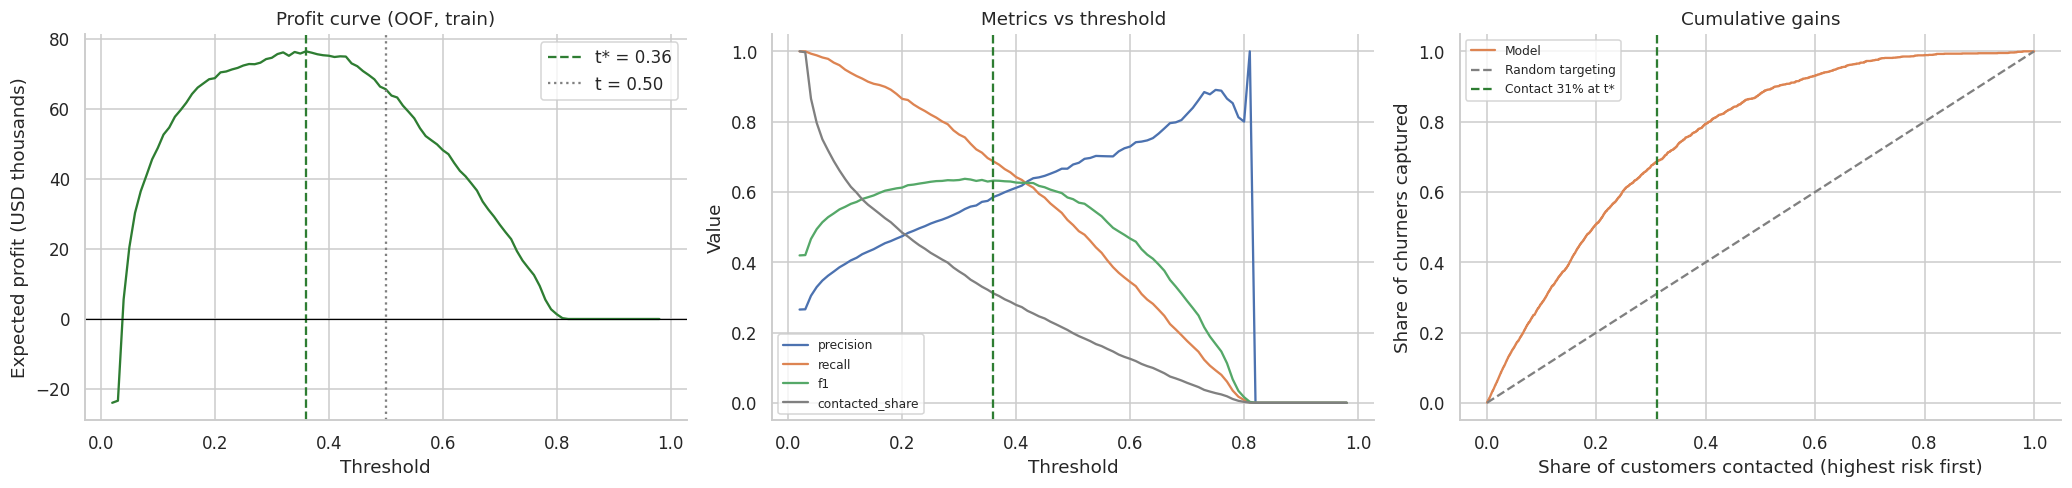

,profit,precision,recall,f1,contacted_share
t = 0.50,65540.9200,0.6780,0.5057,0.5793,0.1979
max F1 (t = 0.31),75576.7600,0.5513,0.7552,0.6373,0.3635
max profit t* = 0.36,76350.5500,0.5855,0.6870,0.6322,0.3113


In [35]:
ECONOMICS = {"horizon_months": 12, "gross_margin": 0.50, "contact_cost": 40.0, "success_rate": 0.30}


def campaign_profit(y_true, proba, monthly_charges, threshold, econ=ECONOMICS):
    contact = proba >= threshold
    value = monthly_charges * econ["horizon_months"] * econ["gross_margin"]
    return float(np.sum(contact * (y_true * econ["success_rate"] * value - econ["contact_cost"])))


monthly_train = TelcoCleaner().transform(X_train)["MonthlyCharges"].to_numpy()
y_train_np = y_train.to_numpy()
thresholds = np.round(np.arange(0.02, 0.99, 0.01), 2)
threshold_curve = pd.DataFrame({
    "threshold": thresholds,
    "profit": [campaign_profit(y_train_np, oof_final, monthly_train, t) for t in thresholds],
    "precision": [precision_score(y_train, oof_final >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(y_train, oof_final >= t) for t in thresholds],
    "f1": [f1_score(y_train, oof_final >= t) for t in thresholds],
    "contacted_share": [(oof_final >= t).mean() for t in thresholds],
})
BUSINESS_THRESHOLD = float(threshold_curve.loc[threshold_curve["profit"].idxmax(), "threshold"])
f1_threshold = float(threshold_curve.loc[threshold_curve["f1"].idxmax(), "threshold"])

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
axes[0].plot(threshold_curve["threshold"], threshold_curve["profit"] / 1000, color="#2E7D32")
axes[0].axvline(BUSINESS_THRESHOLD, color="#2E7D32", ls="--", label=f"t* = {BUSINESS_THRESHOLD:.2f}")
axes[0].axvline(0.5, color="gray", ls=":", label="t = 0.50")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set(xlabel="Threshold", ylabel="Expected profit (USD thousands)", title="Profit curve (OOF, train)")
axes[0].legend()

for metric, color in [("precision", "#4C72B0"), ("recall", "#DD8452"), ("f1", "#55A868"), ("contacted_share", "gray")]:
    axes[1].plot(threshold_curve["threshold"], threshold_curve[metric], label=metric, color=color)
axes[1].axvline(BUSINESS_THRESHOLD, color="#2E7D32", ls="--")
axes[1].set(xlabel="Threshold", ylabel="Value", title="Metrics vs threshold")
axes[1].legend(fontsize=8)

order = np.argsort(-oof_final)
captured = np.cumsum(y_train_np[order]) / y_train_np.sum()
share = np.arange(1, len(order) + 1) / len(order)
axes[2].plot(share, captured, color="#DD8452", label="Model")
axes[2].plot([0, 1], [0, 1], color="gray", ls="--", label="Random targeting")
k = (oof_final >= BUSINESS_THRESHOLD).mean()
axes[2].axvline(k, color="#2E7D32", ls="--", label=f"Contact {k:.0%} at t*")
axes[2].set(xlabel="Share of customers contacted (highest risk first)", ylabel="Share of churners captured",
            title="Cumulative gains")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame({t_name: threshold_curve.set_index("threshold").loc[t] for t_name, t in
              [("t = 0.50", 0.5), (f"max F1 (t = {f1_threshold:.2f})", f1_threshold),
               (f"max profit t* = {BUSINESS_THRESHOLD:.2f}", BUSINESS_THRESHOLD)]}).T

**Findings.**

- The expected profit peaks at **t\* = 0.36**: USD 76.4 k on the training customers (out-of-fold),
  vs 65.5 k at the default 0.5 (+16 %). Contacting fewer customers (higher t) leaves money on the
  table; contacting almost everyone turns the campaign negative because contact costs exceed the
  value saved.
- At t\*, the campaign contacts 31 % of customers and captures 69 % of churners with 59 % precision.
  The threshold that maximizes F1 (0.31) is close, but the profit criterion is what the business
  cares about.
- **Cumulative gains:** contacting the top 31 % by risk captures ≈ 69 % of churners, more than twice
  what random targeting would capture.

**Caveat.** The economics are hypothetical. If the contact cost rises or the success rate falls,
t\* moves up. The Streamlit app recomputes the curve with the user's own values.

## 9. Final Evaluation on the Test Set

Model, hyperparameters and threshold are now fixed. The pipeline is refitted on the full training
set and evaluated once on test.

In [36]:
final_pipeline = make_pipeline(make_lgbm(FINAL_PARAMS)).fit(X_train, y_train)
proba_test = final_pipeline.predict_proba(X_test)[:, 1]
monthly_test = TelcoCleaner().transform(X_test)["MonthlyCharges"].to_numpy()
y_test_np = y_test.to_numpy()


def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba), "pr_auc": average_precision_score(y_true, proba),
            "contacted": int(pred.sum())}


test_metrics = pd.DataFrame({
    "test, t = 0.50": evaluate(y_test_np, proba_test, 0.5),
    f"test, t* = {BUSINESS_THRESHOLD:.2f}": evaluate(y_test_np, proba_test, BUSINESS_THRESHOLD),
    f"CV (OOF), t* = {BUSINESS_THRESHOLD:.2f}": evaluate(y_train_np, oof_final, BUSINESS_THRESHOLD),
}).T
test_metrics

,accuracy,precision,recall,f1,roc_auc,pr_auc,contacted
"test, t = 0.50",0.8055,0.6736,0.5187,0.5861,0.8469,0.6601,288.0000
"test, t* = 0.36",0.7835,0.5765,0.6952,0.6303,0.8469,0.6601,451.0000
"CV (OOF), t* = 0.36",0.7879,0.5855,0.6870,0.6322,0.8479,0.6613,1754.0000


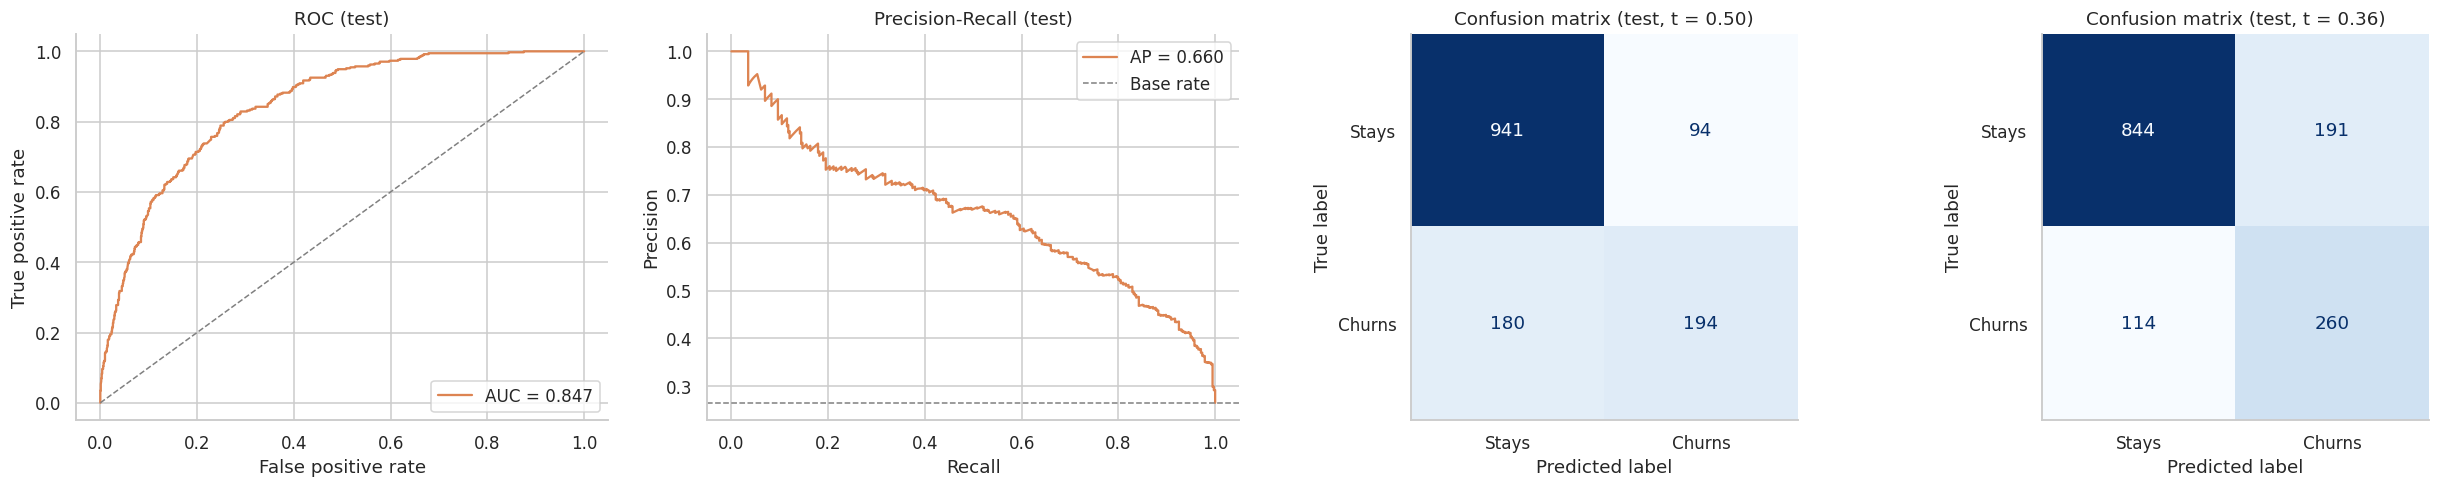

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(23, 4.6))
fpr, tpr, _ = roc_curve(y_test, proba_test)
axes[0].plot(fpr, tpr, color="#DD8452", label=f"AUC = {roc_auc_score(y_test, proba_test):.3f}")
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (test)")
axes[0].legend(loc="lower right")
prec, rec, _ = precision_recall_curve(y_test, proba_test)
axes[1].plot(rec, prec, color="#DD8452", label=f"AP = {average_precision_score(y_test, proba_test):.3f}")
axes[1].axhline(y_test.mean(), color="gray", ls="--", lw=1, label="Base rate")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (test)")
axes[1].legend()
for ax, t in zip(axes[2:], [0.5, BUSINESS_THRESHOLD]):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= t).astype(int), display_labels=["Stays", "Churns"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Confusion matrix (test, t = {t:.2f})")
    ax.grid(False)
plt.tight_layout()
plt.show()

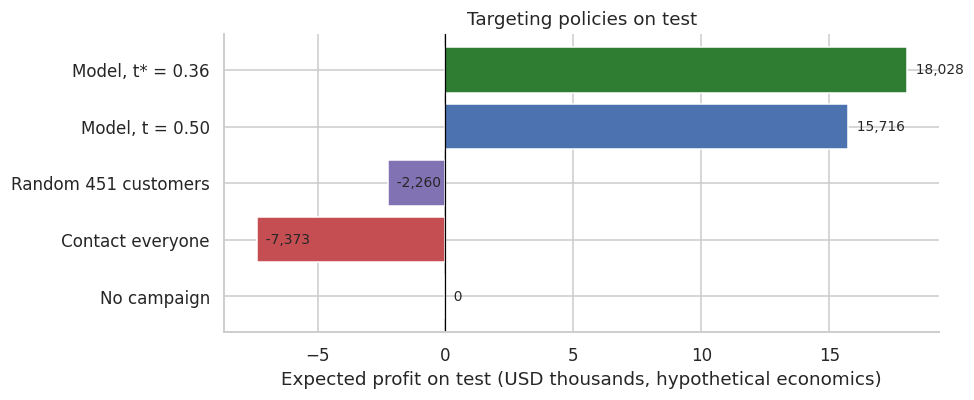

,expected_profit_usd
No campaign,0.0000
Contact everyone,-7373.1800
Random 451 customers,-2260.0620
"Model, t = 0.50",15716.0700
"Model, t* = 0.36",18028.4000


In [38]:
rng = np.random.default_rng(SEED)
n_target = int((proba_test >= BUSINESS_THRESHOLD).sum())
random_profits = [campaign_profit(y_test_np, (rng.permutation(len(y_test_np)) < n_target).astype(float),
                                  monthly_test, 0.5) for _ in range(200)]
policies = pd.Series({
    "No campaign": 0.0,
    "Contact everyone": campaign_profit(y_test_np, np.ones_like(proba_test), monthly_test, 0.5),
    f"Random {n_target} customers": float(np.mean(random_profits)),
    "Model, t = 0.50": campaign_profit(y_test_np, proba_test, monthly_test, 0.5),
    f"Model, t* = {BUSINESS_THRESHOLD:.2f}": campaign_profit(y_test_np, proba_test, monthly_test, BUSINESS_THRESHOLD),
}, name="expected_profit_usd")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(policies.index, policies.values / 1000,
        color=["gray", "#C44E52", "#8172B3", "#4C72B0", "#2E7D32"])
for i, v in enumerate(policies.values):
    ax.text(v / 1000, i, f"  {v:,.0f}", va="center", fontsize=9)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Expected profit on test (USD thousands, hypothetical economics)", title="Targeting policies on test")
plt.tight_layout()
plt.show()
policies.to_frame()

**Findings.**

- Test results match cross-validation (PR-AUC 0.660 vs 0.661, ROC-AUC 0.847 vs 0.848): **no sign of
  overfitting** during tuning and selection.
- At t\* = 0.36 the model contacts 451 of 1,409 test customers, captures **260 of 374 churners
  (recall 0.70)** with precision 0.58. At 0.5 it would capture only 194 (recall 0.52).
- **Business value (hypothetical economics):** the model-based campaign yields ≈ USD 18.0 k on
  this test sample, vs 15.7 k at t = 0.5, −2.3 k for randomly contacting the same number of
  customers and −7.4 k for contacting everyone. The value comes from the ranking, not from the
  campaign itself.
- **Errors:** 191 false alarms (cost: an unnecessary offer) and 114 missed churners (cost: lost
  revenue). Section 10.2 explains one of the misses.

## 10. Explainable AI: SHAP

TreeSHAP computes exact Shapley values for LightGBM. Values are in **log-odds of churn**
(class 1): positive values push the prediction toward churn. Because the model sees one-hot
columns, contributions of the columns of the same original feature are summed, so explanations
are expressed in terms of the 19 raw inputs.

In [39]:
preprocess = final_pipeline[:-1]
lgbm_model = final_pipeline.named_steps["model"]
X_test_t = preprocess.transform(X_test)

explainer = shap.TreeExplainer(lgbm_model)
shap_exp = explainer(X_test_t)
if shap_exp.values.ndim == 3:
    shap_exp = shap_exp[:, :, 1]
base_value = float(np.ravel(shap_exp.base_values)[0])

shap_by_feature = aggregate_by_feature(shap_exp.values, X_test_t.columns)
shap_by_feature.index = X_test.index
test_readable = FeatureBuilder(enabled=USE_ENGINEERED).transform(TelcoCleaner().transform(X_test))
global_shap = shap_by_feature.abs().mean().sort_values(ascending=False)

Markdown(f"Base value (mean log-odds): {base_value:.3f}, i.e. probability {1 / (1 + np.exp(-base_value)):.3f}. "
         f"Additivity check (max |sum SHAP + base - model log-odds|): "
         f"{np.abs(shap_exp.values.sum(1) + base_value - lgbm_model.predict(X_test_t, raw_score=True)).max():.1e}")

Base value (mean log-odds): -1.422, i.e. probability 0.194. Additivity check (max |sum SHAP + base - model log-odds|): 4.0e-15

### 10.1 Global explanation

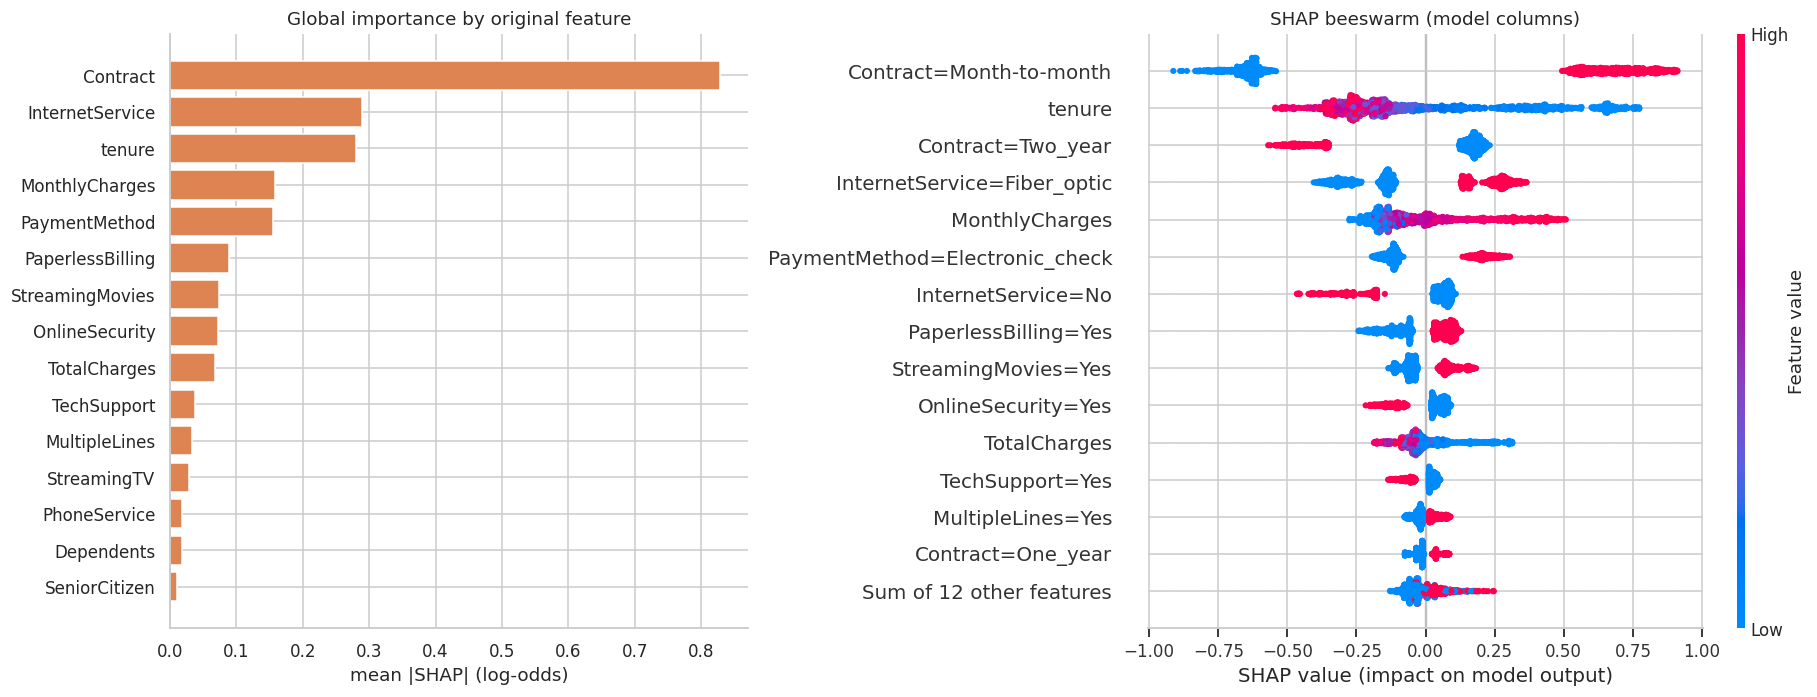

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1.2]})
top = global_shap.head(15)[::-1]
axes[0].barh(top.index, top.values, color="#DD8452")
axes[0].set(xlabel="mean |SHAP| (log-odds)", title="Global importance by original feature")
plt.sca(axes[1])
shap.plots.beeswarm(shap_exp, max_display=15, show=False, plot_size=None)
axes[1].set_title("SHAP beeswarm (model columns)")
plt.tight_layout()
plt.show()

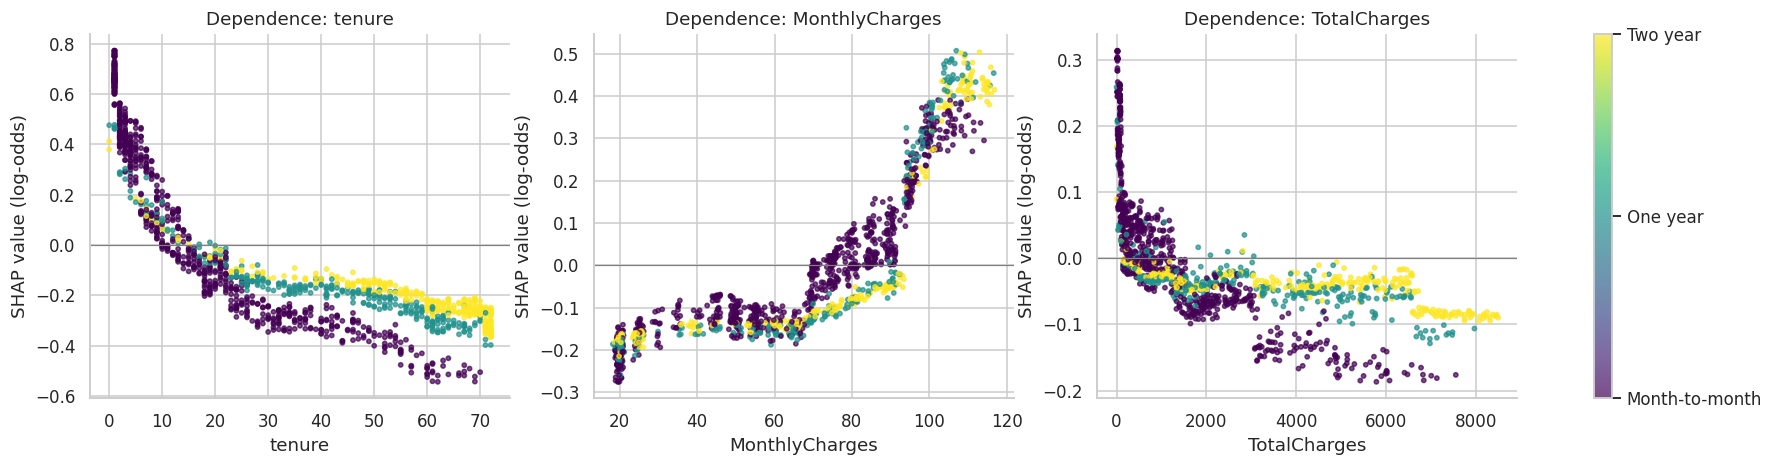

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sc = ax.scatter(X_test_t[col], shap_exp[:, col].values, c=test_readable["Contract"].map(
        {"Month-to-month": 0, "One year": 1, "Two year": 2}), cmap="viridis", s=8, alpha=0.7)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set(xlabel=col, ylabel="SHAP value (log-odds)", title=f"Dependence: {col}")
cbar = fig.colorbar(sc, ax=axes, ticks=[0, 1, 2], fraction=0.02)
cbar.ax.set_yticklabels(["Month-to-month", "One year", "Two year"])
plt.show()

**Findings.**

- **Contract** dominates (≈ 38 % of total |SHAP|): month-to-month adds +0.5 to +1.0 log-odds, a
  two-year contract subtracts about as much.
- Next come **InternetService** (fiber raises risk), **tenure**, **MonthlyCharges** and
  **PaymentMethod** (electronic check raises risk).
- **Dependence plots:** risk falls steeply during the first ≈ 20 months of tenure and then
  flattens; `MonthlyCharges` raises risk only above ≈ 70-80 (fiber tier). Color shows interactions:
  for month-to-month customers (purple), long tenure lowers risk more than for contract customers.
  These non-linear and interaction effects are what LightGBM adds over Logistic Regression.
- The additivity check (≈ 1e-15) confirms base value + SHAP values = model output exactly.

**Correct reading.** SHAP values are in log-odds of churn, relative to the average prediction
(19 %). They describe how the model uses each feature, not what causes churn.

### 10.2 Individual explanations

Two test customers are chosen deliberately: **A**, a churner correctly flagged with the highest
risk, and **B**, a churner the model missed at $t^*$ (false negative). Explaining an error is as
important as explaining a success.

In [42]:
pred_test = (proba_test >= BUSINESS_THRESHOLD).astype(int)
idx_a = X_test.index[np.argmax(np.where((y_test_np == 1) & (pred_test == 1), proba_test, -1))]
fn_mask = (y_test_np == 1) & (pred_test == 0)
idx_b = X_test.index[np.argmin(np.where(fn_mask, proba_test, 2))]
CASES = {"A (true positive)": idx_a, "B (false negative)": idx_b}

case_table = test_readable.loc[list(CASES.values()), [c for c in INPUT_COLUMNS + ENGINEERED if c in test_readable]].T
case_table.columns = list(CASES)
case_table.loc["predicted_probability"] = [proba_test[X_test.index.get_loc(i)] for i in CASES.values()]
case_table.loc["actual_churn"] = [y_test.loc[i] for i in CASES.values()]
case_table

,A (true positive),B (false negative)
gender,Male,Male
SeniorCitizen,Yes,No
Partner,Yes,Yes
Dependents,No,Yes
tenure,1.0000,55.0000
PhoneService,Yes,Yes
MultipleLines,Yes,No
InternetService,Fiber optic,DSL
OnlineSecurity,No,Yes
OnlineBackup,No,Yes


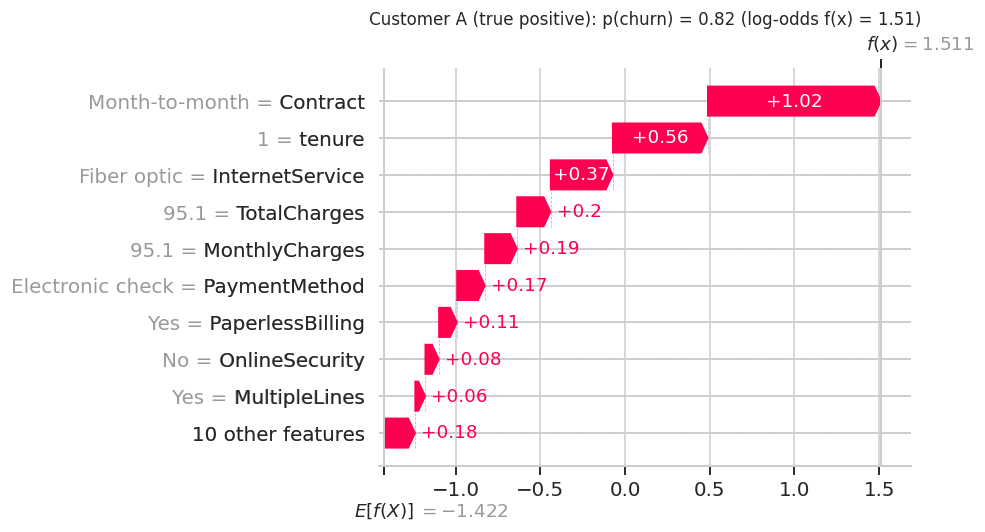

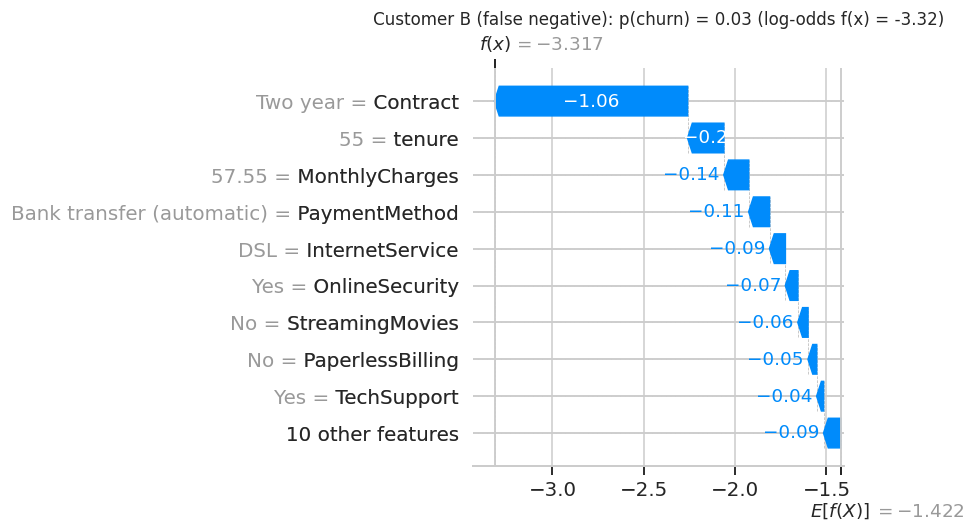

**Customer A (true positive).** Risk increases mainly because of: Contract = Month-to-month; tenure = 1; InternetService = Fiber optic.

**Customer B (false negative).** Risk decreases because of: Contract = Two year; tenure = 55; MonthlyCharges = 57.55.

In [43]:
for label, idx in CASES.items():
    values = shap_by_feature.loc[idx]
    exp = shap.Explanation(values=values.to_numpy(), base_values=base_value,
                           data=test_readable.loc[idx, values.index].to_numpy(), feature_names=list(values.index))
    plt.figure()
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.title(f"Customer {label}: p(churn) = {proba_test[X_test.index.get_loc(idx)]:.2f} "
              f"(log-odds f(x) = {base_value + values.sum():.2f})", fontsize=11)
    plt.gcf().set_size_inches(9, 5)
    plt.tight_layout()
    plt.show()

for label, idx in CASES.items():
    display(Markdown(f"**Customer {label}.** " + explain_in_words(shap_by_feature.loc[idx], test_readable.loc[idx].to_dict())))

**Customer A (p = 0.82, churned).** Starting from the average log-odds (−1.42), the month-to-month
contract adds +1.02, one month of tenure +0.56, fiber internet +0.37 and electronic check +0.17.
Every major factor points to churn: a clear, well-justified alert.

**Customer B (p = 0.03, churned, missed).** A two-year contract (−1.06), 55 months of tenure
(−0.20), moderate charges and automatic bank transfer all point to loyalty. By every signal in the
data this customer looks safe; the reason for leaving (relocation, a competitor offer, a service
incident) is not recorded in the dataset. This is an irreducible error for any model trained on
these features, and the explanation makes it visible instead of hiding it.

**How to explain it to a non-technical person:** "This customer has a high risk mainly because
they pay month to month, joined one month ago and have fiber internet, a combination where about
half of customers leave. Offering a contract with a discount addresses the main factor."

## 11. Explainable AI: LIME

LIME fits a local linear surrogate around one customer by perturbing inputs and querying the
model. It operates on the **raw inputs** (cleaned, before one-hot), and the full pipeline is called
for every perturbed sample, so engineered features are recomputed consistently.
Categorical features are label-encoded only for LIME's sampler and decoded before prediction.

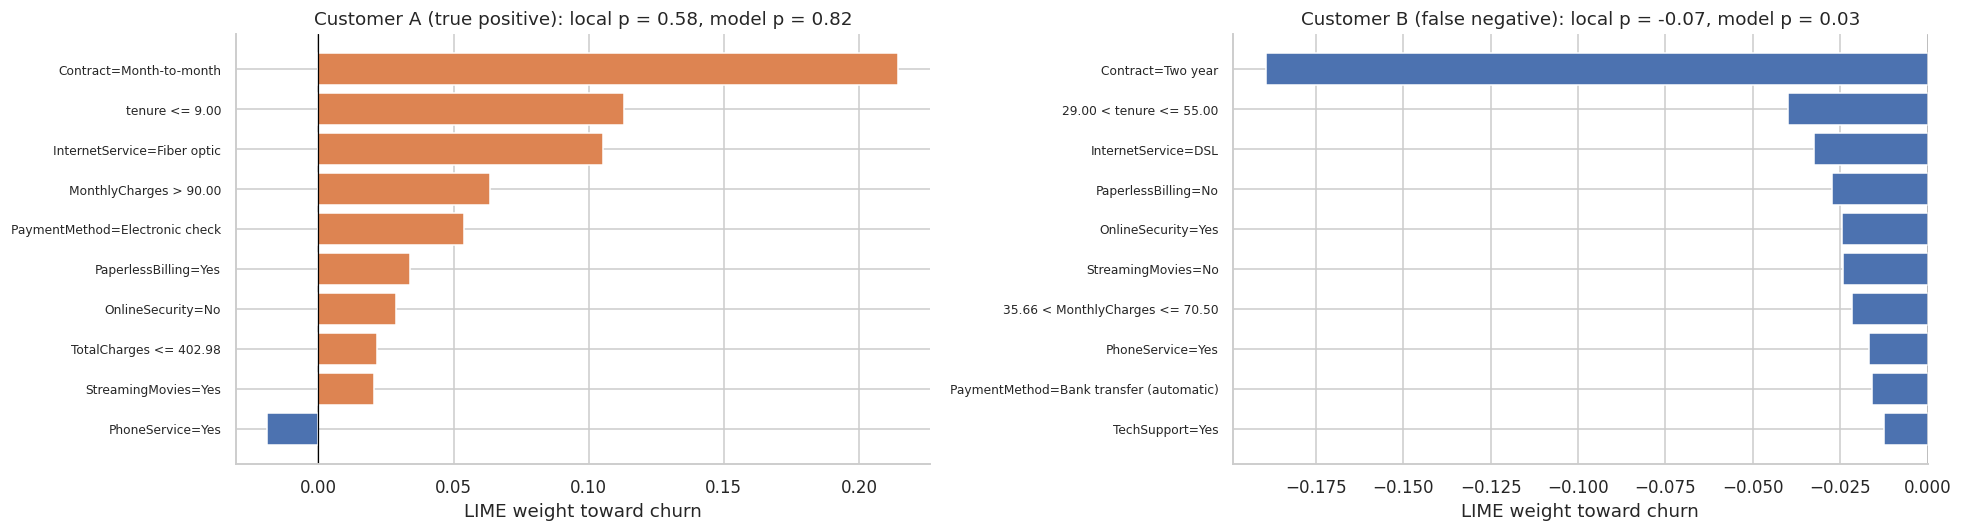

In [44]:
lime_train = TelcoCleaner().transform(X_train)[INPUT_COLUMNS]
LIME_CATEGORIES = {c: sorted(lime_train[c].unique()) for c in CATEGORICAL_INPUTS}
cat_idx = [INPUT_COLUMNS.index(c) for c in CATEGORICAL_INPUTS]


def encode_for_lime(frame):
    out = frame[INPUT_COLUMNS].copy()
    for c in CATEGORICAL_INPUTS:
        out[c] = out[c].map({v: i for i, v in enumerate(LIME_CATEGORIES[c])})
    return out.astype(float).to_numpy()


def lime_predict(array):
    frame = pd.DataFrame(array, columns=INPUT_COLUMNS)
    for c in CATEGORICAL_INPUTS:
        frame[c] = frame[c].round().astype(int).map(dict(enumerate(LIME_CATEGORIES[c])))
    return final_pipeline.predict_proba(frame)


def make_lime(seed):
    return LimeTabularExplainer(
        encode_for_lime(lime_train), feature_names=INPUT_COLUMNS, class_names=["Stays", "Churns"],
        categorical_features=cat_idx, categorical_names={i: LIME_CATEGORIES[c] for i, c in zip(cat_idx, CATEGORICAL_INPUTS)},
        discretize_continuous=True, mode="classification", random_state=seed)


def lime_feature(rule):
    return max((c for c in INPUT_COLUMNS if c in rule), key=len)


lime_explainer = make_lime(SEED)
test_lime = encode_for_lime(TelcoCleaner().transform(X_test))
lime_results = {}
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, (label, idx) in zip(axes, CASES.items()):
    exp = lime_explainer.explain_instance(test_lime[X_test.index.get_loc(idx)], lime_predict, num_features=10,
                                          num_samples=5000, labels=(1,))
    weights = pd.Series(dict(exp.as_list(label=1)))
    lime_results[label] = weights
    w = weights.iloc[::-1]
    ax.barh(w.index, w.values, color=np.where(w.values > 0, "#DD8452", "#4C72B0"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set(xlabel="LIME weight toward churn", title=f"Customer {label}: local p = {exp.local_pred[0]:.2f}, "
           f"model p = {proba_test[X_test.index.get_loc(idx)]:.2f}")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

**Findings.** LIME agrees with SHAP on the main drivers: for customer A, month-to-month contract,
short tenure (≤ 9 months) and fiber push toward churn; for customer B, the two-year contract and
long tenure push away. LIME expresses numeric effects as **intervals** ("tenure ≤ 9"), which are easy
to communicate. Its local surrogate prediction differs from the model's probability (0.58 vs 0.82 for A, −0.07 vs 0.03 for B):
a linear surrogate approximates the model only roughly, and it can even fall outside [0, 1].

### 11.1 Stability

LIME samples randomly, so explanations can change between runs. Each customer is explained with
5 different seeds; stability is measured as the overlap of the top-5 features (Jaccard index) and
the variation of their weights.

In [45]:
stability_rows = []
for label, idx in CASES.items():
    runs = []
    for seed in range(5):
        exp = make_lime(seed).explain_instance(test_lime[X_test.index.get_loc(idx)], lime_predict,
                                               num_features=10, num_samples=5000, labels=(1,))
        runs.append(pd.Series({lime_feature(r): w for r, w in exp.as_list(label=1)}))
    tops = [set(r.abs().nlargest(5).index) for r in runs]
    jaccard = [len(a & b) / len(a | b) for i, a in enumerate(tops) for b in tops[i + 1:]]
    weights = pd.concat(runs, axis=1)
    stability_rows.append({"customer": label, "mean_top5_jaccard": np.mean(jaccard),
                           "min_top5_jaccard": np.min(jaccard),
                           "mean_weight_cv": (weights.std(axis=1) / weights.mean(axis=1).abs()).loc[
                               weights.abs().mean(axis=1).nlargest(5).index].mean()})
pd.DataFrame(stability_rows).set_index("customer")

,mean_top5_jaccard,min_top5_jaccard,mean_weight_cv
customer,,,
A (true positive),1.0000,1.0000,0.0323
B (false negative),1.0000,1.0000,0.0805


**Findings.** With 5,000 perturbation samples the top-5 features are identical across seeds
(Jaccard = 1.0) and the weights vary by only 3-8 %. The explanations are stable for these customers.
The global estimate in Section 12 uses 1,500 samples per customer to save time; averaging over 100
customers compensates for the extra noise.

## 12. Comparison: SHAP, LIME and Feature Importance

### 12.1 Local agreement for the same customers

In [46]:
local_rows = []
for label, idx in CASES.items():
    shap_rank = shap_by_feature.loc[idx].drop(ENGINEERED, errors="ignore").abs()
    lime_rank = pd.Series({lime_feature(r): abs(w) for r, w in lime_results[label].items()})
    common = shap_rank.index
    lime_full = lime_rank.reindex(common).fillna(0)
    top_shap, top_lime = set(shap_rank.nlargest(5).index), set(lime_rank.nlargest(5).index)
    local_rows.append({"customer": label,
                       "top5_overlap": len(top_shap & top_lime),
                       "spearman_rank": stats.spearmanr(shap_rank, lime_full)[0],
                       "top5_SHAP": ", ".join(shap_rank.nlargest(5).index),
                       "top5_LIME": ", ".join(lime_rank.nlargest(5).index)})
pd.DataFrame(local_rows).set_index("customer")

,top5_overlap,spearman_rank,top5_SHAP,top5_LIME
customer,,,,
A (true positive),4,0.8610,"Contract, tenure, InternetService, TotalCharge...","Contract, tenure, InternetService, MonthlyChar..."
B (false negative),3,0.8313,"Contract, tenure, MonthlyCharges, PaymentMetho...","Contract, tenure, InternetService, PaperlessBi..."


### 12.2 Global importance: four methods

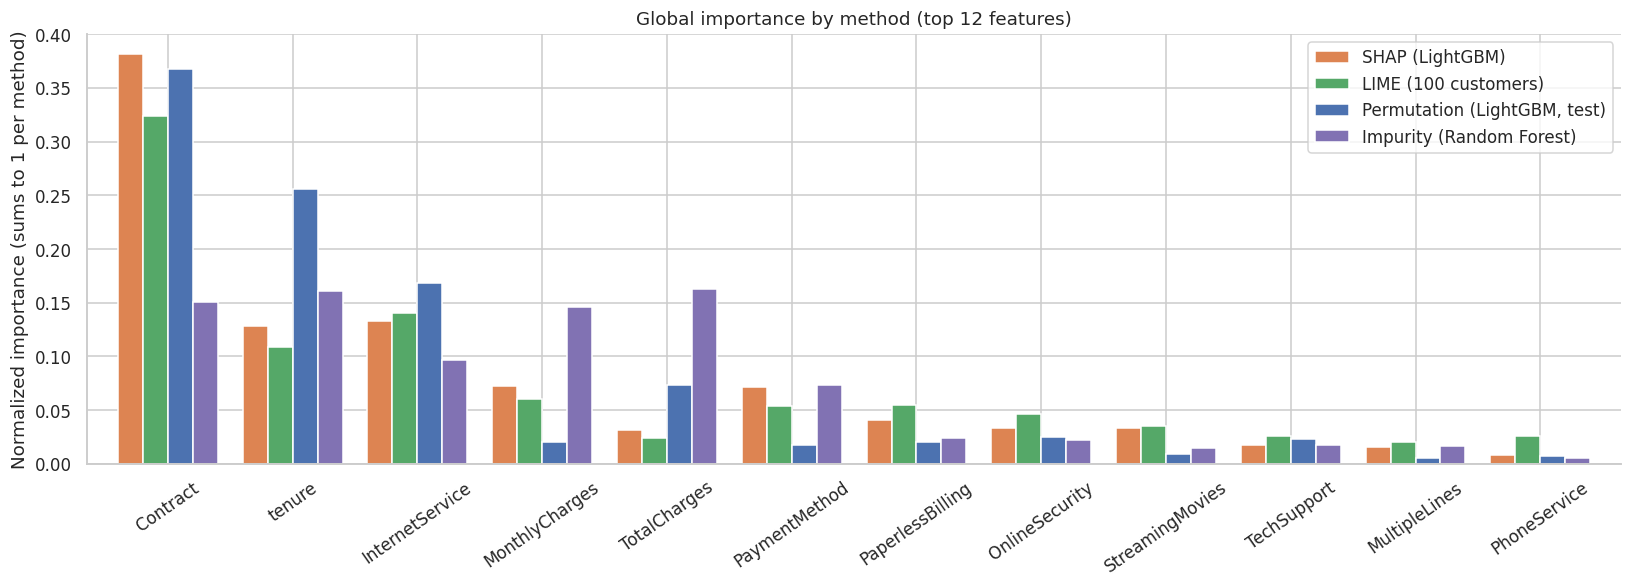

,SHAP (LightGBM),LIME (100 customers),"Permutation (LightGBM, test)",Impurity (Random Forest)
Spearman rank correlation (raw inputs),,,,
SHAP (LightGBM),1.0000,0.9724,0.8946,0.7196
LIME (100 customers),0.9724,1.0000,0.8864,0.6491
"Permutation (LightGBM, test)",0.8946,0.8864,1.0000,0.7565
Impurity (Random Forest),0.7196,0.6491,0.7565,1.0000


,SHAP (LightGBM),LIME (100 customers),"Permutation (LightGBM, test)",Impurity (Random Forest)
Contract,1,1,1,3
tenure,3,3,2,2
InternetService,2,2,3,5
MonthlyCharges,4,4,8,4
TotalCharges,9,11,4,1
PaymentMethod,5,6,9,6
PaperlessBilling,6,5,7,7
OnlineSecurity,8,7,5,8
StreamingMovies,7,8,10,14
TechSupport,10,10,6,10


In [47]:
rf_pipeline = clone(MODELS["Random Forest"]).fit(X_train, y_train)
rf_names = rf_pipeline[:-1].transform(X_train.head()).columns
rf_importance = aggregate_by_feature(rf_pipeline.named_steps["model"].feature_importances_, rf_names).iloc[0]

perm = permutation_importance(final_pipeline, X_test, y_test, scoring="average_precision", n_repeats=10,
                              random_state=SEED, n_jobs=N_JOBS)
perm_importance = pd.Series(perm.importances_mean, index=X_test.columns)

lime_sample = X_test.sample(100, random_state=SEED).index
lime_global = []
for idx in lime_sample:
    exp = lime_explainer.explain_instance(test_lime[X_test.index.get_loc(idx)], lime_predict, num_features=len(INPUT_COLUMNS),
                                          num_samples=1500, labels=(1,))
    lime_global.append({lime_feature(r): abs(w) for r, w in exp.as_list(label=1)})
lime_global = pd.DataFrame(lime_global).fillna(0).mean()

importance = pd.DataFrame({
    "SHAP (LightGBM)": global_shap,
    "LIME (100 customers)": lime_global,
    "Permutation (LightGBM, test)": perm_importance,
    "Impurity (Random Forest)": rf_importance,
}).fillna(0)
importance_norm = importance.clip(lower=0) / importance.clip(lower=0).sum()
top_features = importance_norm.mean(axis=1).sort_values(ascending=False).head(12).index

fig, ax = plt.subplots(figsize=(15, 5.5))
importance_norm.loc[top_features].plot.bar(ax=ax, width=0.8, color=["#DD8452", "#55A868", "#4C72B0", "#8172B3"])
ax.set(ylabel="Normalized importance (sums to 1 per method)", title="Global importance by method (top 12 features)")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

raw_ranks = importance.drop(index=ENGINEERED, errors="ignore").rank(ascending=False)
display(raw_ranks.corr(method="spearman").rename_axis("Spearman rank correlation (raw inputs)"))
importance.rank(ascending=False).astype(int).loc[top_features]

**Findings.**

- **Local agreement:** SHAP and LIME share 4 of 5 (customer A) and 3 of 5 (customer B) top features,
  with rank correlations of 0.86 and 0.83.
- **Global agreement:** SHAP and LIME rank features almost identically (Spearman 0.97); permutation
  importance agrees well (0.89).
- **Random Forest impurity importance** disagrees most (0.65-0.72). It ranks `TotalCharges` first and
  `gender` 9th, although `gender` has no relation with churn. Impurity importance is biased toward
  continuous, high-cardinality features that offer many split points, and it is computed on training
  data. Permutation importance on test ranks `TotalCharges` 4th and `gender` 17th.
- **Most important features across methods:** Contract, tenure, InternetService, then MonthlyCharges,
  PaymentMethod and OnlineSecurity.

**Similarities and differences between SHAP and LIME.** Both are model-agnostic in concept, local,
and agree on the main drivers. SHAP is exact for tree models, additive (contributions sum to the
prediction) and consistent, with a solid game-theory basis; it gives global views for free. LIME
fits a local linear surrogate on random perturbations: it is intuitive (rules such as
"tenure ≤ 9") but approximate, sensitive to sampling and to the kernel width.

**Limitations of both.** They explain the model, not reality, and imply no causality ("contract
reduces churn" is a hypothesis to test with an experiment). They assume features can vary
independently: LIME perturbs `TotalCharges` independently of `tenure`, creating unrealistic customers,
and SHAP's interventional values face the same issue with correlated features. One-hot encoding
requires aggregation to stay interpretable, as done here.

## 13. Export Artifacts

Everything the Streamlit app needs is exported; the app loads these files and never retrains.

| File | Content |
|:--|:--|
| `model.joblib` | Full fitted pipeline (cleaning, features, preprocessing, LightGBM) |
| `telco_churn.py` | Module required to unpickle and use the pipeline |
| `metadata.json` | Threshold, economics, final params, metrics, input schema, versions |
| `results/*.csv` | Model comparison, optimizer trials and summary, Pareto front, threshold curve, importances |
| `data/telco_churn.csv` | Raw dataset for the EDA dashboard |
| `data/lime_reference.csv` | Cleaned training inputs used to build the LIME explainer in the app |

In [48]:
import shutil

out = ARTIFACTS_DIR
(out / "results").mkdir(parents=True, exist_ok=True)
(out / "data").mkdir(parents=True, exist_ok=True)

joblib.dump(final_pipeline, out / "model.joblib", compress=3)
shutil.copy("telco_churn.py", out / "telco_churn.py")
raw.to_csv(out / "data/telco_churn.csv", index=False)
lime_train.to_csv(out / "data/lime_reference.csv", index=False)

model_comparison.to_csv(out / "results/model_comparison.csv")
strategy_comparison.to_csv(out / "results/strategy_comparison.csv")
optimizer_table.to_csv(out / "results/optimizer_summary.csv")
hpo_trials.to_csv(out / "results/hpo_trials.csv", index=False)
mo_trials.to_csv(out / "results/pareto_trials.csv", index=False)
pareto_latency.to_csv(out / "results/pareto_latency.csv", index=False)
threshold_curve.to_csv(out / "results/threshold_curve.csv", index=False)
importance.to_csv(out / "results/global_importance.csv")
test_metrics.to_csv(out / "results/test_metrics.csv")

metadata = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "model": "LightGBM (NSGA-II, one-standard-error selection)",
    "final_params": FINAL_PARAMS,
    "business_threshold": BUSINESS_THRESHOLD,
    "economics": ECONOMICS,
    "economics_note": "Hypothetical assumptions for illustration, not estimated from data.",
    "base_rate_train": float(base_rate),
    "cv_metrics": final_comparison.loc["Selected: NSGA-II 1-SE"].to_dict(),
    "test_metrics": {k: {m: float(v) for m, v in row.items()} for k, row in test_metrics.iterrows()},
    "confusion_matrix_test": {
        "t_0.50": confusion_matrix(y_test, proba_test >= 0.5).tolist(),
        "t_business": confusion_matrix(y_test, proba_test >= BUSINESS_THRESHOLD).tolist(),
    },
    "pareto": {"one_se_threshold": float(one_se_threshold), "reference_pr_auc": float(ref_pr_auc),
               "selected_trial": int(selected.trial), "knee_trial": int(knee.trial)},
    "input_schema": {
        "columns": INPUT_COLUMNS,
        "categorical": {c: sorted(raw[c].astype(str).unique()) for c in CATEGORICAL_INPUTS},
        "numeric": {c: {"min": float(pd.to_numeric(raw[c], errors="coerce").min()),
                        "max": float(pd.to_numeric(raw[c], errors="coerce").max())} for c in NUMERIC_INPUTS},
    },
    "versions": {lib: version(lib) for lib in ["scikit-learn", "lightgbm", "shap", "lime", "pandas", "numpy"]},
    "seed": SEED,
}
(out / "metadata.json").write_text(json.dumps(metadata, indent=2, default=float))

reloaded = joblib.load(out / "model.joblib")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], proba_test)
pd.DataFrame([(str(p.relative_to(out)), round(p.stat().st_size / 1024, 1)) for p in sorted(out.rglob("*")) if p.is_file()],
             columns=["file", "size_kb"])

,file,size_kb
0,data/lime_reference.csv,569.5000
1,data/telco_churn.csv,948.5000
2,metadata.json,4.3000
3,model.joblib,46.0000
4,results/global_importance.csv,1.8000
5,results/hpo_trials.csv,54.6000
6,results/model_comparison.csv,1.2000
7,results/optimizer_summary.csv,0.5000
8,results/pareto_latency.csv,0.2000
9,results/pareto_trials.csv,6.8000


## 14. Conclusions

**Data and pipeline**

- Clean dataset after three deterministic rules. Churn is driven by contract type, tenure, internet
  service, charges and payment method.
- Cleaning lives inside the pipeline, the test set was isolated from start to finish, and every
  learned step is fitted within CV folds: no leakage.
- Engineered features were tested and rejected with evidence.

**Models and optimization**

- Logistic Regression is a strong baseline (PR-AUC 0.661). Tuned LightGBM reaches 0.665-0.670 and
  captures non-linear and interaction effects, but the margin is within one standard error: a
  linear model remains a credible, simpler fallback.
- Grid, Random and TPE reach statistically equal results; TPE is the most efficient (fastest, most
  consistent). Learning rate is the decisive hyperparameter.
- NSGA-II and the one-standard-error rule yield a model with **76 % fewer leaves** and the same
  ranking quality.

**Decision and value**

- The model is well calibrated, so its probabilities can be shown directly.
- A profit-based threshold (0.36) raises recall from 0.52 to 0.70 on test and, under the declared
  hypothetical economics, outperforms the default threshold, random targeting and mass campaigns.
- SHAP and LIME agree on why customers are flagged, can explain both successes and errors, and
  reveal the bias of impurity-based importance.

**Limitations and next steps:** static snapshot data (no time dimension), hypothetical economics,
no data on campaign response (an uplift model would require experimental data), and predictive
importance is not causal. Monitoring for drift and an A/B test of the retention campaign are the
natural next steps before production use.